# A complete scientific workflow

*An end-to-end case study, from raw behavior to a defended model*

<center> <img src="./images/HSSM_logo.png"> </center>

Welcome to the scientific workflow tutorial. This tutorial starts with a basic experimental dataset and we will inch from a very simple HSSM model iteratively toward a model that captures many of the main patterns we can identify in our dataset.

Along the way we try to achieve the following balance:

1. Illustrate how HSSM can be used for real scientific workflows. HSSM helps us with model building, running the stats, and reporting results.
2. Stay readable end to end by deferring conceptually advanced features to the dedicated tutorials in the [documentation](https://lnccbrown.github.io/HSSM/).

This tutorial is the capstone of the learning path rather than its entry point: it assumes you have already built and sampled a model, as covered in [the HSSM tutorial](https://lnccbrown.github.io/HSSM/tutorials/main_tutorial/). If you are looking for your first look at HSSM, start there.

## Run this tutorial

<a href="https://colab.research.google.com/github/lnccbrown/HSSM/blob/main/docs/tutorials/scientific_workflow_hssm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open this notebook in Google Colab"></a>

On Colab, uncomment and run the installation cell below once, then restart the runtime. For local setup, GPU extras, and troubleshooting see the [Installation guide](https://lnccbrown.github.io/HSSM/getting_started/installation/).


##### Install hssm

In [1]:
# %pip install hssm

##### Download tutorial data

In [2]:
# # Data Files
# !wget -P  data/carney_workshop_2025_data/ https://raw.githubusercontent.com/lnccbrown/HSSM/main/scientific_workflow_hssm/data/carney_workshop_2025_full.parquet
# !wget -P  data/carney_workshop_2025_data/ https://raw.githubusercontent.com/lnccbrown/HSSM/main/scientific_workflow_hssm/data/carney_workshop_2025_modeling.parquet
# !wget -P  data/carney_workshop_2025_data/ https://raw.githubusercontent.com/lnccbrown/HSSM/main/scientific_workflow_hssm/data/carney_workshop_2025_parameters.pkl

# # Presampled traces
# !wget -P  idata/basic_ddm/ https://raw.githubusercontent.com/lnccbrown/HSSM/main/scientific_workflow_hssm/idata/basic_ddm/traces.nc
# !wget -P  idata/ddm_hier/ https://raw.githubusercontent.com/lnccbrown/HSSM/main/scientific_workflow_hssm/idata/ddm_hier/traces.nc
# !wget -P  idata/angle_hier/ https://raw.githubusercontent.com/lnccbrown/HSSM/main/scientific_workflow_hssm/idata/angle_hier/traces.nc
# !wget -P  idata/angle_hier_v2/ https://raw.githubusercontent.com/lnccbrown/HSSM/main/scientific_workflow_hssm/idata/angle_hier_v2/traces.nc
# !wget -P  idata/angle_hier_v3/ https://raw.githubusercontent.com/lnccbrown/HSSM/main/scientific_workflow_hssm/idata/angle_hier_v3/traces.nc
# !wget -P  idata/angle_hier_v4/ https://raw.githubusercontent.com/lnccbrown/HSSM/main/scientific_workflow_hssm/idata/angle_hier_v4/traces.nc
# !wget -P  idata/angle_v5/ https://raw.githubusercontent.com/lnccbrown/HSSM/main/scientific_workflow_hssm/idata/angle_v5/traces.nc

## Start of Tutorial

#### Load modules

In [3]:
import warnings

import arviz as az
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

warnings.filterwarnings(
    "ignore",
    message="Numba will use object mode.*",
    category=UserWarning,
)
warnings.filterwarnings(
    "ignore",
    message="indexing past lexsort depth.*",
    category=pd.errors.PerformanceWarning,
)
warnings.filterwarnings(
    "ignore",
    message="Estimated shape parameter of Pareto.*",
    category=UserWarning,
)
warnings.filterwarnings(
    "ignore",
    message="There are not enough devices.*",
    category=UserWarning,
)
warnings.filterwarnings(
    "ignore",
    message="`init=.* is ignored by `nuts_sampler=.*",
    category=UserWarning,
)

import hssm

#### Load workshop data

In [4]:
def load_data(
    filename_base: str, folder: str = "data"
) -> tuple[pd.DataFrame, pd.DataFrame, dict]:
    """Load saved simulation data and parameters from files.

    Parameters
    ----------
    filename_base : str
        Base filename used when saving files
    folder : str, optional
        Folder containing saved files, by default "data"

    Returns
    -------
    tuple[pd.DataFrame, pd.DataFrame, dict]
        Contains:
        - DataFrame with modeling data
        - DataFrame with full data
        - Dict containing group and subject parameters
    """
    df_modeling = pd.read_parquet(f"{folder}/{filename_base}_modeling.parquet")
    return df_modeling

In [5]:
workshop_data = load_data(
    filename_base="carney_workshop_2025", folder="scientific_workflow_hssm/data/"
)

#### Load Plotting Utilities

In [6]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


def pretty_column_label(column: str | None) -> str:
    """Convert a data column name into a compact plot label."""
    if column is None:
        return "Condition"
    return column.replace("_", " ").title()


def plot_rt_by_choice(
    df: pd.DataFrame,
    categorical_column: str | None = None,
    colors: dict[str, str] | dict[int, str] | None = None,
    ax: plt.Axes | None = None,
):
    """Plot signed-RT histograms, optionally split by a categorical column."""
    if categorical_column is None:
        ax.hist(
            df["rt"] * df["response"],
            bins=np.linspace(-5, 5, 50),
            histtype="step",
            density=True,
            color="tab:blue",
        )
    else:
        for cond in df[categorical_column].unique():
            df_cond = df[df[categorical_column] == cond]
            ax.hist(
                df_cond["rt"] * df_cond["response"],
                bins=np.linspace(-5, 5, 50),
                label=str(cond),
                histtype="step",
                density=True,
                color=colors[cond],
            )
    ax.set_xlabel("RT * Choice")
    ax.set_ylabel("Density")
    return ax


def inset_bar_plot(
    df: pd.DataFrame,
    categorical_column: str,
    response_options: list[int],
    colors: dict[str, str] | dict[int, str] | None = None,
    ax: plt.Axes | None = None,
):
    """Draw an inset bar plot of choice proportions per response option."""
    axins = inset_axes(ax, width="42%", height="42%", loc="upper right", borderpad=0.35)
    bar_width = 0.45
    for j, resp in enumerate(response_options):
        for k, cond in enumerate(df[categorical_column].unique()):
            k_displace = -1 if k == 0 else 1
            df_cond = df[df[categorical_column] == cond]
            prop = df_cond[df_cond.response == resp].shape[0] / len(df_cond)
            axins.bar(
                (resp + ((bar_width / 2) * k_displace)),
                prop,
                width=bar_width,
                fill=False,
                edgecolor=colors[cond],
                label=f"Response {resp}",
            )
    axins.set_xticks(response_options)
    axins.set_ylim(0, 1)
    axins.set_yticks([0.0, 0.5, 1])
    axins.set_title("Choice prop.", fontsize=6)
    axins.tick_params(axis="both", which="major", labelsize=5, pad=1)
    axins.set_xlabel("")
    axins.set_ylabel("")
    return ax


def inset_bar_plot_vertical(
    df: pd.DataFrame,
    categorical_column: str,
    response_options: list[int],
    colors: dict[str, str] | dict[int, str] | None = None,
    ax: plt.Axes | None = None,
):
    """Draw an inset horizontal bar plot of mean RT per response option."""
    axins = inset_axes(ax, width="42%", height="42%", loc="upper right", borderpad=0.35)
    bar_width = 0.45
    for j, resp in enumerate(response_options):
        for k, cond in enumerate(df[categorical_column].unique()):
            k_displace = -1 if k == 0 else 1
            df_cond = df[df[categorical_column] == cond]
            rt_mean = (df_cond[df_cond.response == resp]).rt.mean()
            axins.barh(
                (resp + ((bar_width / 2) * k_displace)),
                rt_mean,
                height=bar_width,
                fill=False,
                edgecolor=colors[cond],
                label=f"Response {resp}",
            )

    axins.set_yticks(response_options)
    axins.set_xticks([0.0, 1.0, 2.0])
    axins.set_title("Mean RT", fontsize=6)
    axins.tick_params(axis="both", which="major", labelsize=5, pad=1)
    axins.set_xlabel("")
    axins.set_ylabel("")
    return ax


def plot_rt_hists(
    df: pd.DataFrame,
    by_participant: bool = True,
    split_by_column: str | None = None,
    inset_plot: str | None = "choice_proportion",
    cols: int = 5,
):
    """Plot RT histograms, optionally faceted by participant and category."""
    if split_by_column is not None:
        colors = {
            cond: color
            for cond, color in zip(
                df[split_by_column].unique(),
                ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"],
            )
        }
    else:
        colors = None

    split_label = pretty_column_label(split_by_column)

    if by_participant:
        participants = df["participant_id"].unique()
        rows = (len(participants) + cols - 1) // cols
        fig, axes = plt.subplots(
            rows,
            cols,
            sharey=True,
            sharex=True,
            figsize=(cols * 2.7, rows * 2.15),
        )
        axes = axes.flatten()
        for i, pid in enumerate(participants):
            ax = axes[i]
            df_part = df[df["participant_id"] == pid]
            ax = plot_rt_by_choice(df_part, split_by_column, colors, ax)

            if split_by_column is not None and inset_plot == "choice_proportion":
                ax = inset_bar_plot(
                    df_part, split_by_column, df["response"].unique(), colors, ax
                )
            elif split_by_column is not None and inset_plot == "rt_mean":
                ax = inset_bar_plot_vertical(
                    df_part, split_by_column, df["response"].unique(), colors, ax
                )

        for j in range(i + 1, len(axes)):
            axes[j].set_visible(False)

        if split_by_column is not None:
            handles, labels = axes[0].get_legend_handles_labels()
            fig.legend(
                handles,
                labels,
                title=split_label,
                loc="upper left",
                bbox_to_anchor=(0.01, 0.98),
                fontsize="small",
            )

        fig.suptitle(f"RT, Split by {split_label} and Participant", y=0.995)
        fig.subplots_adjust(top=0.88, hspace=0.55, wspace=0.35)
        plt.show()
    else:
        fig, ax = plt.subplots(1, 1, figsize=(6, 4))
        ax = plot_rt_by_choice(df, split_by_column, colors, ax)

        if split_by_column is not None and inset_plot == "choice_proportion":
            ax = inset_bar_plot(
                df, split_by_column, df["response"].unique(), colors, ax
            )
        elif split_by_column is not None and inset_plot == "rt_mean":
            ax = inset_bar_plot_vertical(
                df, split_by_column, df["response"].unique(), colors, ax
            )

        if split_by_column is not None:
            ax.legend(title=split_label, loc="best", fontsize="small")
        fig.tight_layout()
        fig.suptitle(f"RT by Trial, Split by {split_label}", y=1.02)
        plt.show()


def plot_grouped_traces(traces, *, show_divergences: bool = True) -> None:
    """Plot every posterior variable in readable summary and participant groups."""
    summary_suffixes = ("_Intercept", "_mu", "_sigma")
    posterior_names = list(traces.posterior.data_vars)
    summary_names = [
        name for name in posterior_names if name.endswith(summary_suffixes)
    ]
    participant_names = [name for name in posterior_names if name not in summary_names]
    groups = (
        ("Population-level and group-scale parameters", summary_names),
        ("Participant-level effects", participant_names),
    )

    for title, var_names in groups:
        if not var_names:
            continue

        visuals = {
            "label": {"fontsize": 7, "labelpad": 2},
            "ticklabels": {"labelsize": 7},
        }
        if not show_divergences:
            visuals["divergence"] = False

        az.plot_trace_dist(
            traces,
            var_names=var_names,
            compact=True,
            visuals=visuals,
            figure_kwargs={
                "figsize": (13, max(6, 1.25 * len(var_names))),
                "layout": "constrained",
            },
        )
        figure = plt.gcf()
        figure.suptitle(title, fontsize=12)
        trace_axes = [axis for axis in figure.axes if axis.get_position().x0 > 0.5]
        for axis in trace_axes:
            axis.set_ylabel("")
            if axis is not trace_axes[-1]:
                axis.set_xlabel("")
        plt.show()

## Exploratory Data Analysis

<center> <img src="images/Experiment.png" height=300 width=700> </center>


Now that we are done preparing the setup, let's get to the meat of it! The picture above gives us a bit of an idea, where the dataset that we are going to work with below comes from (alert: the backstory may or may not be real). 

**20** subjects, performed **250** trials each of a basic *Random dot motion* task. The task seemingly had two important manipulations. 

1. A **costly fail** condition, in which subjects get punished for mistakes.
2. A trial by trail manipulation of **difficulty** (in the **Random dot motion** task, this refers to degree of coherence with which the dots move in a particular direction)

Let's take a look at the actual dataframe.

#### Why start with EDA?

*How do observable behavioral effects relate to the latent cognitive processes involved in a decision?* Patterns you can see in raw behavior — response-time shifts, choice-ratio asymmetries — are the observable signatures of latent parameters you cannot observe directly. Looking carefully at the data *before* modeling turns those patterns into concrete parameter hypotheses, and that is exactly how this tutorial proceeds: watch for a **decision threshold** hypothesis emerging from the costly-fail condition, and a **bias/stickiness** hypothesis emerging from lagged responses.

*(This framing question is inherited from the Winterbrain 2025 workshop — [archived here](https://lnccbrown.github.io/HSSM/archive/hssm_tutorial_workshop_2/).)*

In [7]:
workshop_data

,response,rt,participant_id,trial,costly_fail_condition,continuous_difficulty,response_l1
0,1,0.556439,0,1,1,-0.277337,0
1,1,0.741682,0,2,0,-0.810919,1
2,1,0.461832,0,3,0,-0.673330,1
3,1,0.626154,0,4,0,0.755445,1
4,1,0.651677,0,5,1,0.136755,1
...,...,...,...,...,...,...,...
4995,1,1.039342,19,246,0,-0.612223,-1
4996,1,1.587827,19,247,0,0.732396,1
4997,1,0.668594,19,248,1,-0.175321,1
4998,1,1.616471,19,249,0,-0.630447,1


#### Adding a few columns

As part of prep work for plotting etc. we will add a few columns here. These will be motivated later (close your eyes :)).

In [8]:
# Binary version of difficulty
workshop_data["bin_difficulty"] = workshop_data["continuous_difficulty"].apply(
    lambda x: "high" if x > 0 else "low"
)

# I want a a ordinal variable that is composed of 5 quantile levels of difficulty
workshop_data["quantile_difficulty"] = pd.qcut(
    workshop_data["continuous_difficulty"], 3, labels=["-1", "0", "1"]
)

workshop_data["quantile_difficulty_binary"] = pd.qcut(
    workshop_data["continuous_difficulty"], 2, labels=["-1", "1"]
)

# Slightly
workshop_data["response_l1_plotting"] = workshop_data["response_l1"].apply(
    lambda x: str(-1) if x == -1 else str(1)
)

#### Most basic reaction time plot

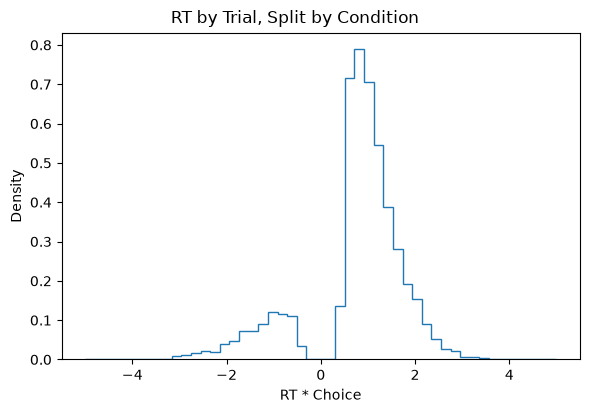

In [9]:
plot_rt_hists(
    workshop_data, by_participant=False, split_by_column=None, inset_plot=None
)

So far so good. Looking at the global reaction time pattern, it does seem commensurate with what we might expect out of basic Sequential Sampling Model (SSM). The basic DDM might be a good start here.

## Basic Model: DDM

<center> <img src="images/DDM_with_params_pic.png" height="500" width="500"> </center>

The picture above illustrates the basic [Drift Diffusion Model](https://pmc.ncbi.nlm.nih.gov/articles/PMC2474742/). Note the parameters,

1. `v` the drift rate (how much evidence do I collect on average per unit of time)
2. `a` the boundary separation (how much evidence do I need to commit to a choice)
3. `z` how biased am I toward a particular choice a priori
4. `ndt` (we will simply call it `t` below), the delay between being exposed to a stimulus and starting the actual evidence accumulation process

The models below use `noncentered=False` (the centered parameterization) — see [Centered vs. non-centered parameterizations](https://lnccbrown.github.io/HSSM/tutorials/centered_vs_noncentered_basic_logic/) for when each choice samples better.


In [10]:
BasicDDMModel = hssm.HSSM(
    data=workshop_data,
    model="ddm",
    loglik_kind="approx_differentiable",
    global_formula="y ~ 1",
    noncentered=False,
)

Model initialized successfully.


In [11]:
BasicDDMModel

Hierarchical Sequential Sampling Model
Model: ddm

Response variable: rt,response
Likelihood: approx_differentiable
Observations: 5000

Parameters:

v:
    Formula: v ~ 1
    Priors:
        v_Intercept ~ Normal(mu: 0.0, sigma: 0.25)
    Link: identity
    Explicit bounds: (-3.0, 3.0)

a:
    Formula: a ~ 1
    Priors:
        a_Intercept ~ Normal(mu: 1.4, sigma: 0.25)
    Link: identity
    Explicit bounds: (0.3, 2.5)

z:
    Formula: z ~ 1
    Priors:
        z_Intercept ~ Normal(mu: 0.5, sigma: 0.25)
    Link: identity
    Explicit bounds: (0.0, 1.0)

t:
    Formula: t ~ 1
    Priors:
        t_Intercept ~ Normal(mu: 1.0, sigma: 0.25)
    Link: identity
    Explicit bounds: (0.0, 2.0)


Lapse probability: 0.05
Lapse distribution: Uniform(lower: 0.0, upper: 20.0)

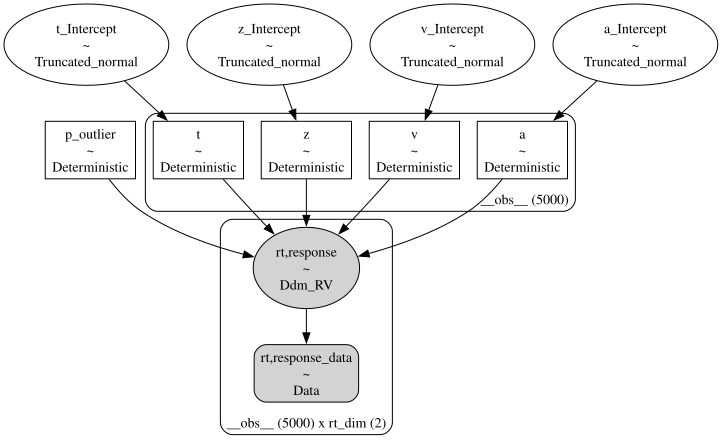

In [12]:
BasicDDMModel.graph()

In [13]:
try:
    # Load pre-computed traces
    BasicDDMModel.restore_traces(
        traces="scientific_workflow_hssm/idata/basic_ddm/traces.nc"
    )
except Exception:
    # Sample posterior
    basic_ddm_idata = BasicDDMModel.sample(
        chains=2,
        sampler="numpyro",
        tune=500,
        draws=500,
    )

    # Sample posterior predictive
    BasicDDMModel.sample_posterior_predictive(draws=200, safe_mode=True)

    # Save Model
    BasicDDMModel.save_model(
        model_name="basic_ddm",
        allow_absolute_base_path=True,
        base_path="scientific_workflow_hssm/idata/",
        save_traces_only=True,
    )

Using default initvals. 



NUTS[numpyro]: [v_Intercept, a_Intercept, z_Intercept, t_Intercept]


  0%|          | 0/1000 [00:00<?, ?it/s]

warmup:   5%|▌         | 50/1000 [00:01<00:24, 38.96it/s, 3 steps of size 3.08e-03. acc. prob=0.73]

warmup:  10%|█         | 100/1000 [00:02<00:18, 49.09it/s, 3 steps of size 1.53e-02. acc. prob=0.76]

...

sample:  95%|█████████▌| 950/1000 [00:18<00:00, 55.11it/s, 3 steps of size 3.72e-01. acc. prob=0.92]

sample: 100%|██████████| 1000/1000 [00:19<00:00, 54.68it/s, 3 steps of size 3.72e-01. acc. prob=0.92]

sample: 100%|██████████| 1000/1000 [00:19<00:00, 52.55it/s, 3 steps of size 3.72e-01. acc. prob=0.92]


We recommend running at least 4 chains for robust computation of convergence diagnostics


dt=None, we use the traces assigned to the HSSM object as datatree.


In [14]:
BasicDDMModel.traces

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:      (chain: 2, draw: 500)
│       Coordinates:
│         * chain        (chain) int64 16B 0 1
│         * draw         (draw) int64 4kB 0 1 2 3 4 5 6 ... 493 494 495 496 497 498 499
│       Data variables:
│           t_Intercept  (chain, draw) float64 8kB ...
│           v_Intercept  (chain, draw) float64 8kB ...
│           z_Intercept  (chain, draw) float64 8kB ...
│           a_Intercept  (chain, draw) float64 8kB ...
│       Attributes:
│           created_at:                  2026-10-14T15:19:09.527142+00:00
│           creation_library:            ArviZ
│           creation_library_version:    1.3.1
│           creation_library_language:   Python
│           sample_dims:                 ['chain', 'draw']
│           inference_library:           numpyro
│           inference_library_version:   0.22.0
│           sampling_time:               39.491232
│           tuning_steps:                500
│           modeling_interface:          bambi
│           modeling_interface_version:  0.20.1.dev19+g2fa070cba
├── Group: /sample_stats
│       Dimensions:          (chain: 2, draw: 500)
│       Coordinates:
│         * chain            (chain) int64 16B 0 1
│         * draw             (draw) int64 4kB 0 1 2 3 4 5 6 ... 494 495 496 497 498 499
│       Data variables:
│           acceptance_rate  (chain, draw) float64 8kB ...
│           step_size        (chain, draw) float64 8kB ...
│           diverging        (chain, draw) bool 1kB ...
│           energy           (chain, draw) float64 8kB ...
│           n_steps          (chain, draw) int64 8kB ...
│           tree_depth       (chain, draw) int64 8kB 3 4 3 3 3 3 4 3 ... 3 4 3 4 3 3 4 2
│           lp               (chain, draw) float64 8kB ...
│       Attributes:
│           created_at:                  2026-10-14T15:19:09.530507+00:00
│           creation_library:            ArviZ
│           creation_library_version:    1.3.1
│           creation_library_language:   Python
│           sample_dims:                 ['chain', 'draw']
│           modeling_interface:          bambi
│           modeling_interface_version:  0.20.1.dev19+g2fa070cba
├── Group: /observed_data
│       Dimensions:          (__obs__: 5000, rt,response_dim: 2)
│       Coordinates:
│         * __obs__          (__obs__) int64 40kB 0 1 2 3 4 ... 4995 4996 4997 4998 4999
│         * rt,response_dim  (rt,response_dim) int64 16B 0 1
│       Data variables:
│           rt,response      (__obs__, rt,response_dim) float64 80kB 0.5564 1.0 ... 1.0
│       Attributes:
│           created_at:                  2026-10-14T15:19:09.531037+00:00
│           creation_library:            ArviZ
│           creation_library_version:    1.3.1
│           creation_library_language:   Python
│           sample_dims:                 []
│           modeling_interface:          bambi
│           modeling_interface_version:  0.20.1.dev19+g2fa070cba
├── Group: /constant_data
│       Attributes:
│           created_at:                  2026-10-14T15:19:09.531098+00:00
│           creation_library:            ArviZ
│           creation_library_version:    1.3.1
│           creation_library_language:   Python
│           sample_dims:                 []
│           modeling_interface:          bambi
│           modeling_interface_version:  0.20.1.dev19+g2fa070cba
├── Group: /log_likelihood
│       Dimensions:      (chain: 2, draw: 500, __obs__: 5000)
│       Coordinates:
│         * chain        (chain) int64 16B 0 1
│         * draw         (draw) int64 4kB 0 1 2 3 4 5 6 ... 493 494 495 496 497 498 499
│         * __obs__      (__obs__) int64 40kB 0 1 2 3 4 5 ... 4995 4996 4997 4998 4999
│       Data variables:
│           rt,response  (chain, draw, __obs__) float64 40MB -0.4088 -0.1905 ... -0.5002
│       Attributes:
│           modeling_interface:          bambi
│           modeling_interface_version:  0.20.1.dev19+g2fa070cba
└── Group: /posterior_predictive
     

In [15]:
az.summary(BasicDDMModel.traces)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
t_Intercept,0.3274,0.0056,0.32,0.34,504,656,1.00,0.00025,0.00017
v_Intercept,0.942,0.023,0.9,0.98,472,381,1.00,0.0011,0.00062
z_Intercept,0.4664,0.0066,0.46,0.48,466,568,1.01,0.00031,0.00019
a_Intercept,1.0174,0.0089,1,1,566,582,1.00,0.00038,0.00024


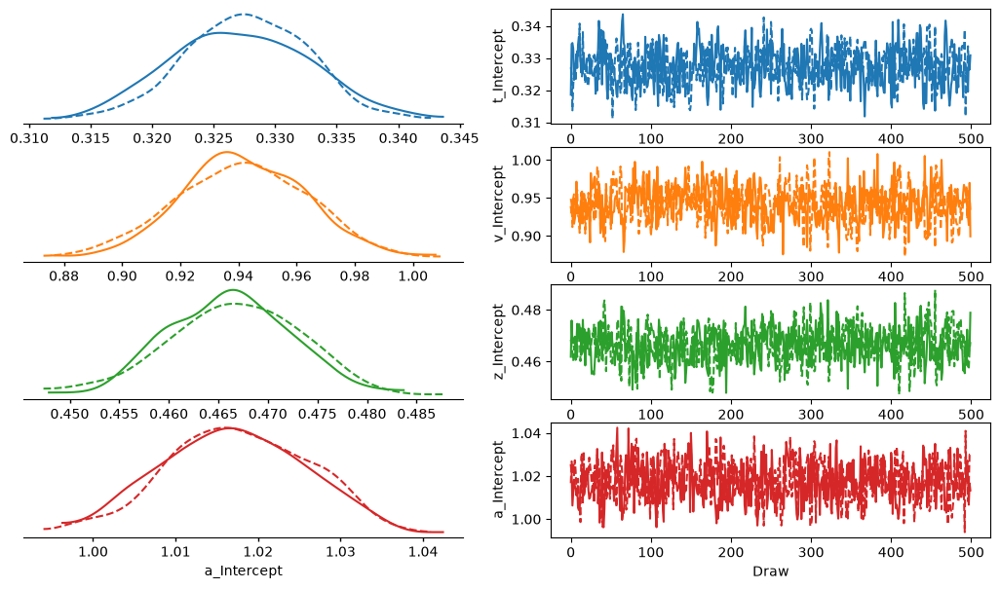

In [16]:
az.plot_trace_dist(BasicDDMModel.traces)

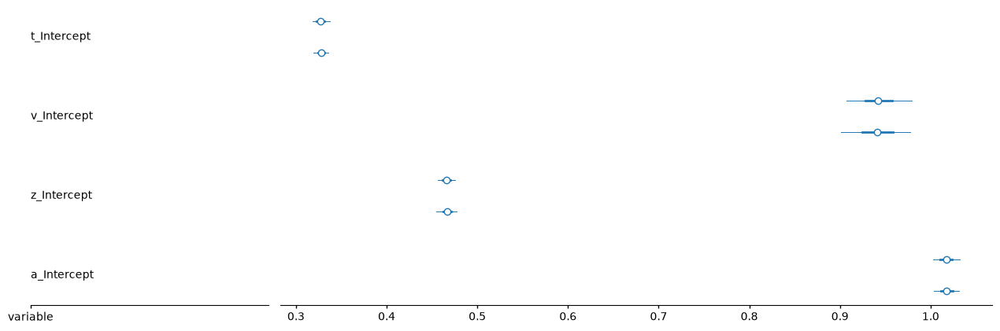

In [17]:
az.plot_forest(BasicDDMModel.traces)
plt.tight_layout()

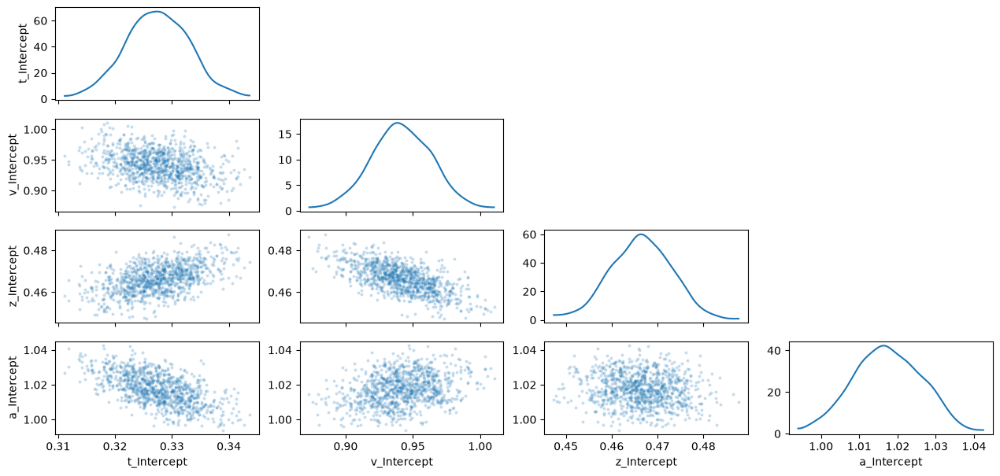

In [18]:
az.plot_pair(
    BasicDDMModel.traces,
    marginal_kind="kde",
    visuals={"scatter": {"alpha": 0.25, "s": 8}},
)

ArviZ 1.2 displays the off-diagonal pairwise relationships as posterior-draw scatter plots. The diagonal panels retain KDE marginals, so the figure shows both parameter dependence and marginal uncertainty.

No posterior_predictive samples found. Generating posterior_predictive samples using the provided DataTree object and the original data. This will modify the provided DataTree object, or if not provided, the traces object stored inside the model.


ipykernel_90485/2453130330.py:1: FutureWarning: plot_predictive_mean/plot_predictive_samples are deprecated; use uncertainty=None (mean only), 'samples', 'band', or 'both' instead.
  ax = hssm.plotting.plot_model_cartoon(


Output()

Output()

Output()

Output()

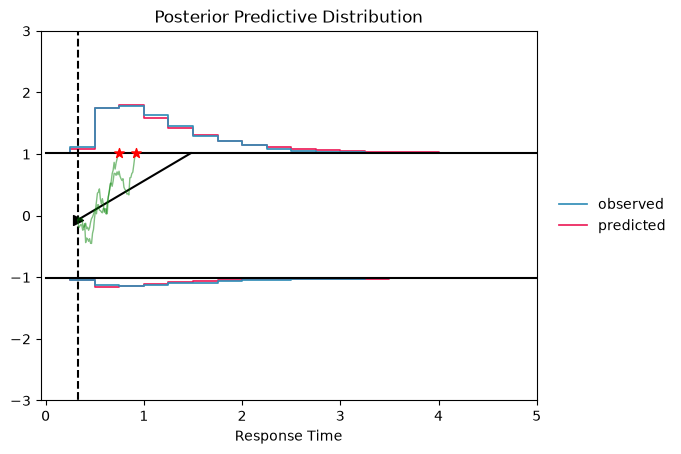

In [19]:
ax = hssm.plotting.plot_model_cartoon(
    BasicDDMModel,
    n_samples=10,
    bins=20,
    plot_predictive_mean=True,
    plot_predictive_samples=False,
    # extra arguments for the underlying plot_model_cartoon() function
    n_trajectories=2,
);

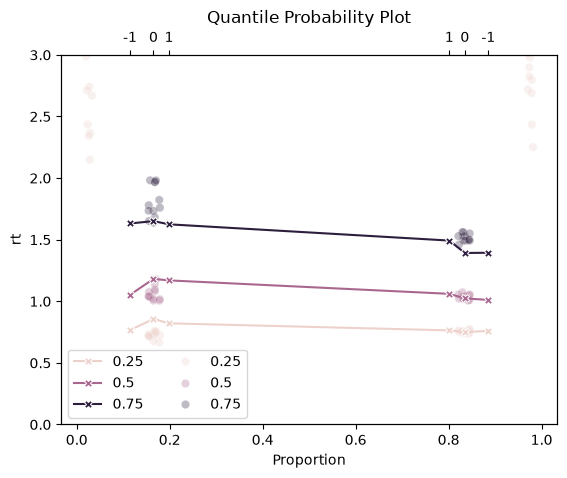

In [20]:
ax = hssm.plotting.plot_quantile_probability(
    BasicDDMModel,
    cond="quantile_difficulty",
)
ax.set_ylim(0, 3);
# ax.set_xlim(-0.1, 1.1);

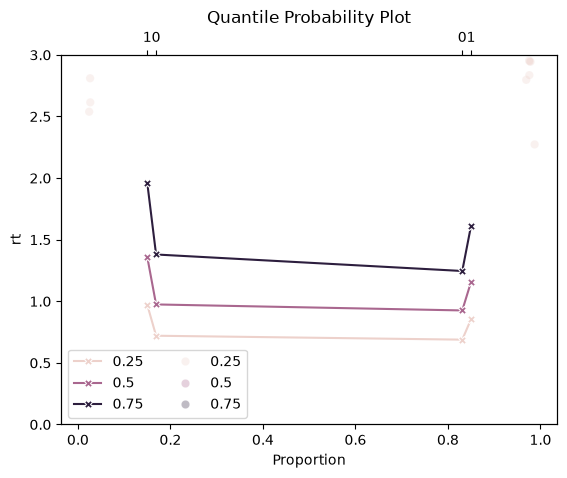

In [21]:
ax = hssm.plotting.plot_quantile_probability(
    BasicDDMModel,
    cond="costly_fail_condition",
)
ax.set_ylim(0, 3);

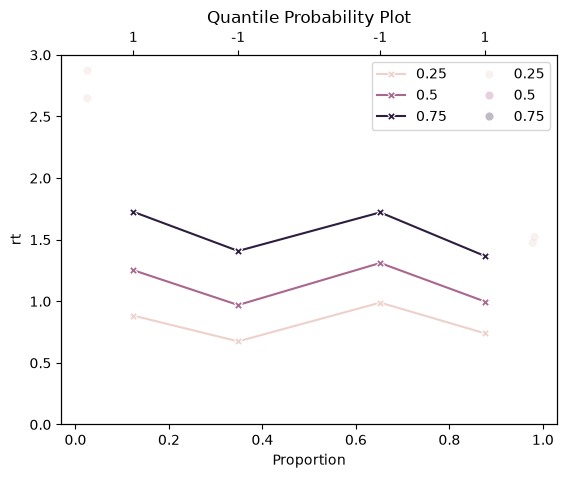

In [22]:
ax = hssm.plotting.plot_quantile_probability(
    BasicDDMModel,
    cond="response_l1_plotting",
)
ax.set_ylim(0, 3);

numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges
numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges
numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges
numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges
numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges
numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges
numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges
numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges
numpy/li

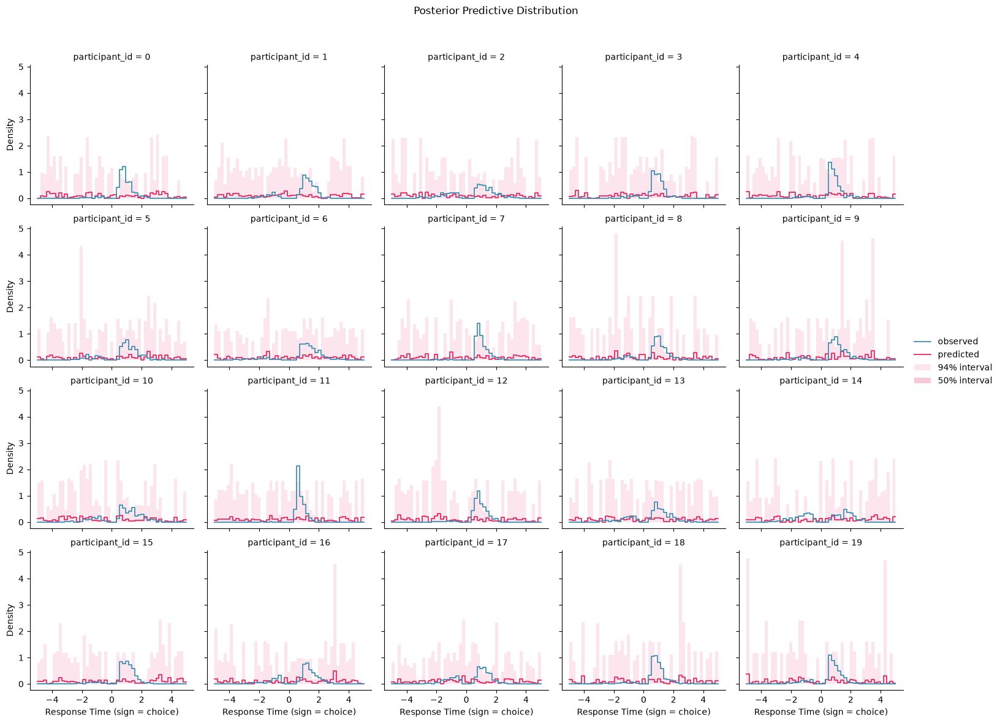

In [23]:
# Posterior predictive
BasicDDMModel.plot_predictive(
    step=True, col="participant_id", col_wrap=5, bins=np.linspace(-5, 5, 50)
)

#### Taking stock

We can observe a few patterns here. 

- First, cleary the reaction time distributions are not the same for every subject, we need to account for that.
- Second, I does seem like the tail of the reaction time distribution is more graceful in for our predictions than it is in the original subject data. (This was less clear when looking only at the global pattern...)

We will now adjust our model to tackle these patterns one by one. Let's begin by specializing our parameters by subject. 

In **Bayesian Inference** we approach this by introducing a **Hierarchy**, we assume that subject level parameters derive from a common **group distribution**.

Inference then proceeds over the parameters of this group distribution, as well as the subject wise parameters. 

Hierarchies serve as a form of **regularization** of our parameter estimates, the group distribution allows us to share information between the single subject parameters estimates. 

You don't **have** to use a hierarchy, we could introduce a subject wise parameterization e.g. by simply treating `participant_id` as a **categorical** variable / collection of **dummy** variables without using any notion of a group distribution (and you are welcome to try this).

## DDM Hierarchical

Moving on to our first hierarchical model. As a first step, we will use our `global_formula` argument to `(1|participant_id)`, which is equivalent to `1 + (1|participant_id)`,
(use `0 + (1|participant_id)` is you explicitly don't want to create an intercept).

This will make all parameters of our model hierarchical.

In [24]:
DDMHierModel = hssm.HSSM(
    data=workshop_data,
    model="ddm",
    loglik_kind="approx_differentiable",
    global_formula="y ~ (1|participant_id)",  # New
    noncentered=False,
)

Model initialized successfully.


In [25]:
try:
    # Load pre-computed traces
    DDMHierModel.restore_traces(
        traces="scientific_workflow_hssm/idata/ddm_hier/traces.nc"
    )
except Exception:
    # Sample posterior
    ddm_hier_idata = DDMHierModel.sample(
        chains=2,
        sampler="numpyro",
        tune=500,
        draws=500,
    )

    # Sample posterior predictive
    DDMHierModel.sample_posterior_predictive(draws=200, safe_mode=True)

    # Save Model
    DDMHierModel.save_model(
        model_name="ddm_hier",
        allow_absolute_base_path=True,
        base_path="scientific_workflow_hssm/idata/",
        save_traces_only=True,
    )

Using default initvals. 



NUTS[numpyro]: [v_Intercept, v_1|participant_id_sigma, v_1|participant_id, a_Intercept, a_1|participant_id_sigma, a_1|participant_id, z_Intercept, z_1|participant_id_sigma, z_1|participant_id, t_Intercept, t_1|participant_id_sigma, t_1|participant_id]


  0%|          | 0/1000 [00:00<?, ?it/s]

warmup:   0%|          | 0/1000 [00:11<?, ?it/s, 1023 steps of size 2.70e-04. acc. prob=0.57]

warmup:   2%|▏         | 16/1000 [00:12<13:01,  1.26it/s, 1023 steps of size 2.64e-04. acc. prob=0.59]

...

sample: 100%|██████████| 1000/1000 [04:23<00:00,  3.79it/s, 63 steps of size 8.96e-02. acc. prob=0.84]

We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


dt=None, we use the traces assigned to the HSSM object as datatree.


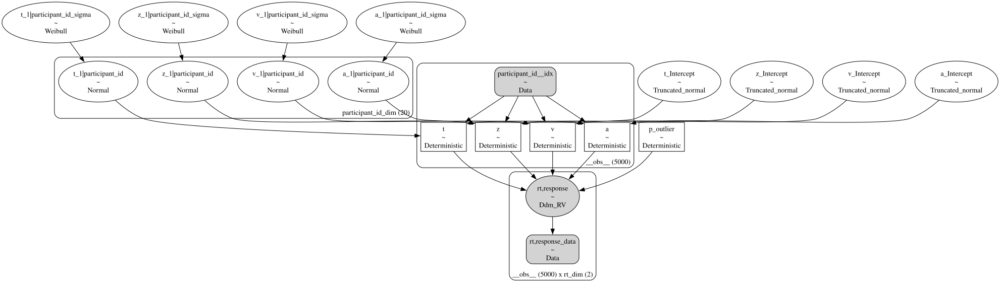

In [26]:
DDMHierModel.graph()

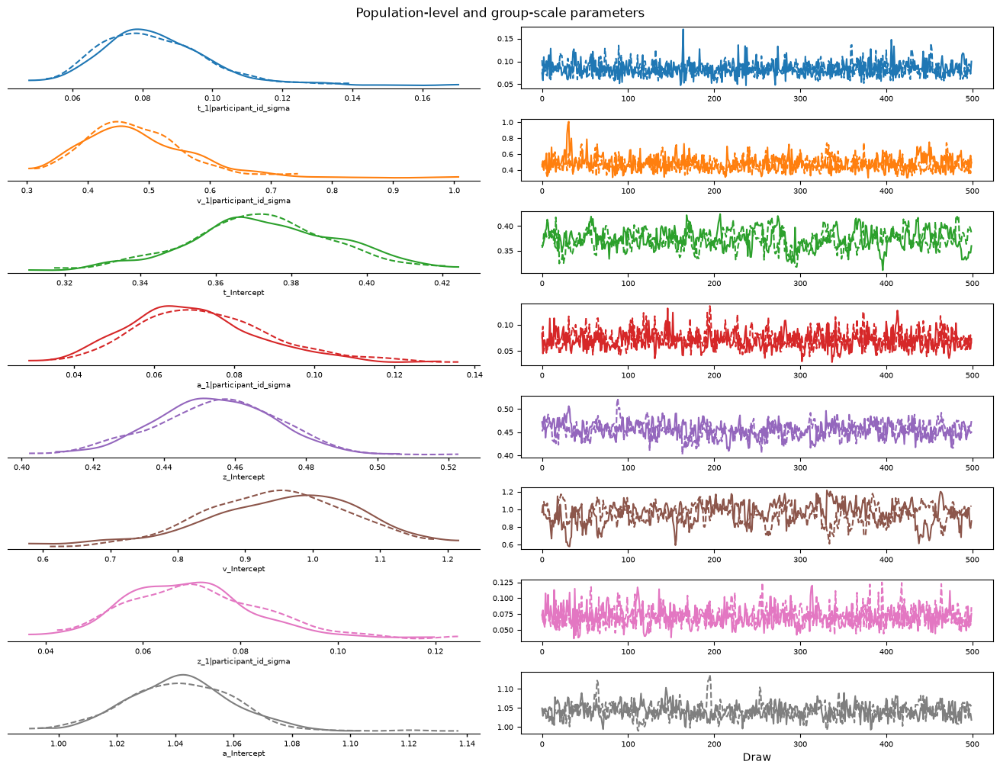

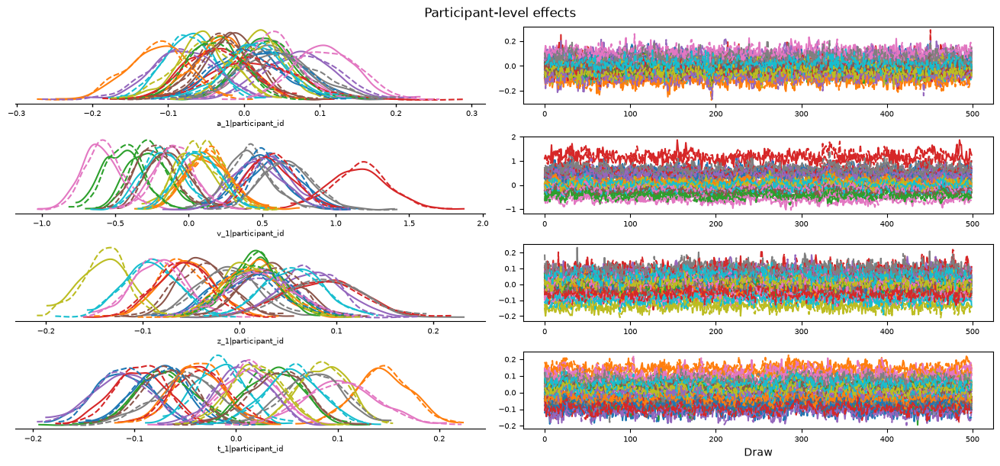

In [27]:
plot_grouped_traces(DDMHierModel.traces)

No posterior_predictive samples found. Generating posterior_predictive samples using the provided DataTree object and the original data. This will modify the provided DataTree object, or if not provided, the traces object stored inside the model.


ipykernel_90485/1285283063.py:1: FutureWarning: plot_predictive_mean/plot_predictive_samples are deprecated; use uncertainty=None (mean only), 'samples', 'band', or 'both' instead.
  ax = hssm.plotting.plot_model_cartoon(


Output()

Output()

Output()

Output()

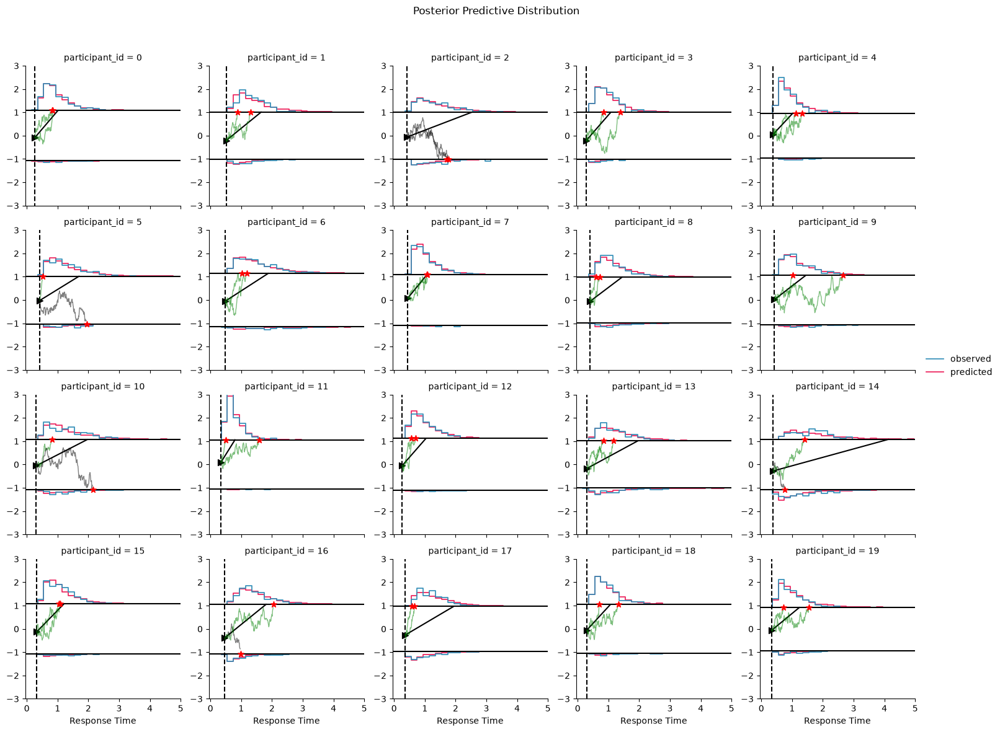

In [28]:
ax = hssm.plotting.plot_model_cartoon(
    DDMHierModel,
    col="participant_id",
    col_wrap=5,
    n_samples=100,
    bin_size=0.2,
    plot_predictive_mean=True,
    # color_pp_mean = "red",
    # color_pp = "black",
    plot_predictive_samples=False,
    # extra arguments for the underlying plot_model_cartoon() function
    n_trajectories=2,
);

#### Comparing Parameter Loadings

In [29]:
az.summary(
    DDMHierModel.traces, filter_vars="like", var_names=["~participant_id"]
).sort_index()

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
a_Intercept,1.042,0.019,1,1.1,325,468,1.00,0.0011,0.001
t_Intercept,0.373,0.019,0.34,0.4,189,201,1.01,0.0014,0.00084
v_Intercept,0.95,0.11,0.76,1.1,137,182,1.01,0.0097,0.006
z_Intercept,0.455,0.017,0.43,0.48,244,295,1.01,0.0011,0.00065


In [30]:
az.summary(BasicDDMModel.traces).sort_index()

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
a_Intercept,1.0174,0.0089,1,1,566,582,1.00,0.00038,0.00024
t_Intercept,0.3274,0.0056,0.32,0.34,504,656,1.00,0.00025,0.00017
v_Intercept,0.942,0.023,0.9,0.98,472,381,1.00,0.0011,0.00062
z_Intercept,0.4664,0.0066,0.46,0.48,466,568,1.01,0.00031,0.00019


The mean parameters of our models are de facto quite similar. Allowing subject wise variation however dramatically improved our fit to the data!

#### Quantitative Model Comparison

In [31]:
az.compare({"DDM": BasicDDMModel.traces, "DDM Hierarchical": DDMHierModel.traces})

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
DDM Hierarchical,0,0.0,0.0,NaN,,1 k̂ > 0.67,74.6,-5000.0,76.0,1.0
DDM,1,-690.0,33.0,1.0,,,5.1,-5600.0,75.0,0.0


#### Comparing predictions

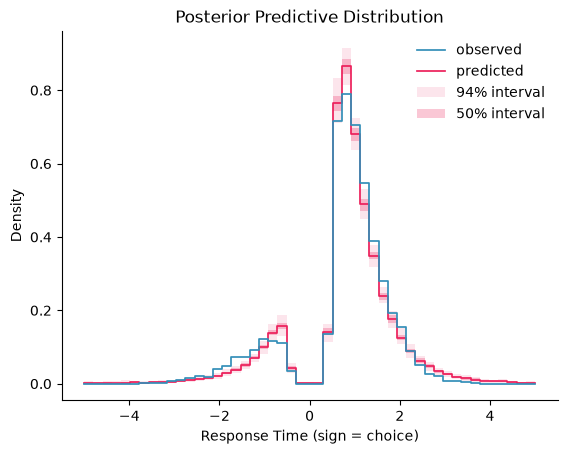

In [32]:
# Posterior predictive
DDMHierModel.plot_predictive(step=True, col_wrap=5, bins=np.linspace(-5, 5, 50));

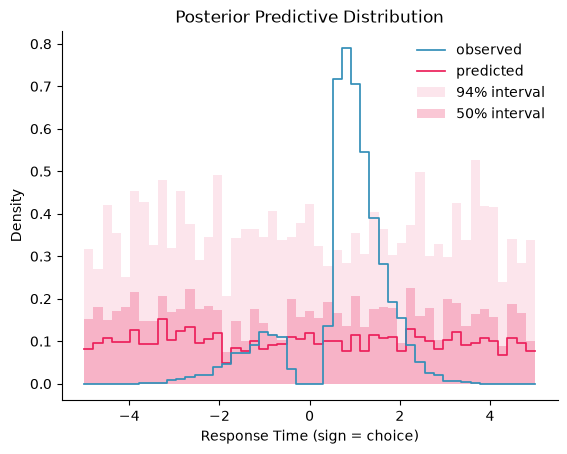

In [33]:
# Posterior predictive
BasicDDMModel.plot_predictive(step=True, col_wrap=5, bins=np.linspace(-5, 5, 50));

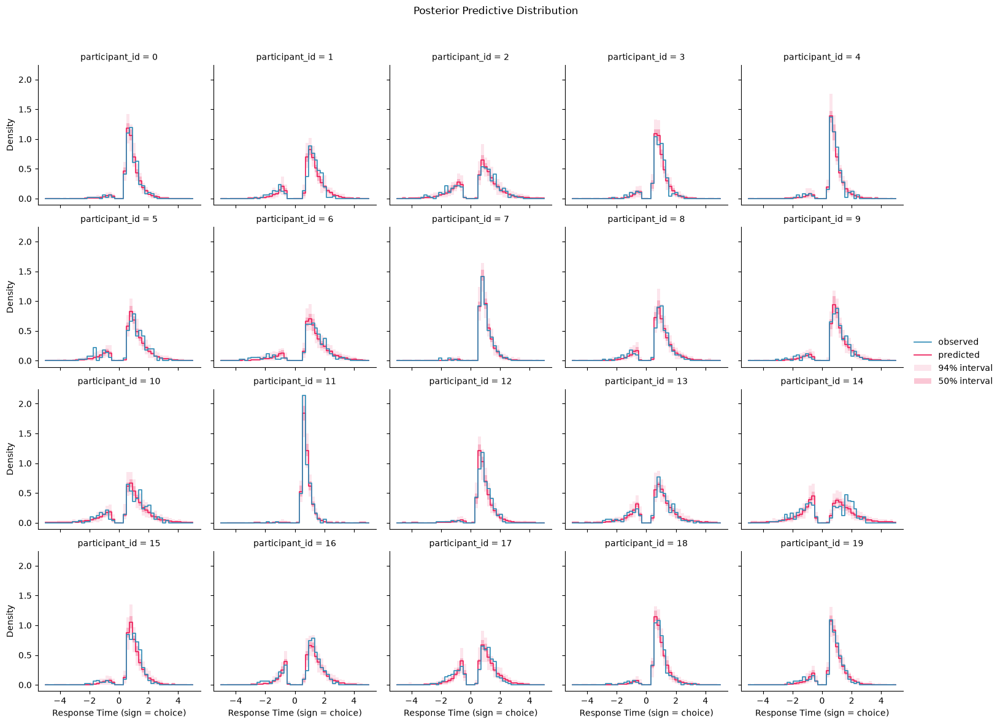

In [34]:
# Posterior predictive
DDMHierModel.plot_predictive(
    step=True, col="participant_id", col_wrap=5, bins=np.linspace(-5, 5, 50)
)

#### Taking Stock

Let's take stock again of any obvious pontential for improving our model here. We are now capturing the data much better subject by subject, however looking closely, 

it seems like the tail behavior of the observed and the predicted data is somewhat different, for a few subjects. 

The particularly suspicious subjest, are:

- `participant_id = 1`
- `participant_id = 14`
- `participant_id = 15`
- `participant_id = 17`


It seems that for these (and there are others) participants, the model predicted data has a wider tail than what we actually observe in our dataset. 

This will motivate a change in the Sequential Sampling Model that we apply. 

## Angle Model Hierarchical

Given what we concluded about the tail behavior of the observed RTs, we will adjust our SSM, to allow for **linear collapsing bounds**. HSSM ships with a such a model,
and we can apply it to our data simple by changing the `model` argument. The corresponding model is called `angle` model in our lingo, and is illustrated below conceptually.



<center> <img src="images/ANGLE_with_params_pic.png" height=500 width=500> </center>


In [35]:
AngleHierModel = hssm.HSSM(
    data=workshop_data,
    model="angle",
    loglik_kind="approx_differentiable",
    global_formula="y ~ (1|participant_id)",
    noncentered=False,
)

Model initialized successfully.


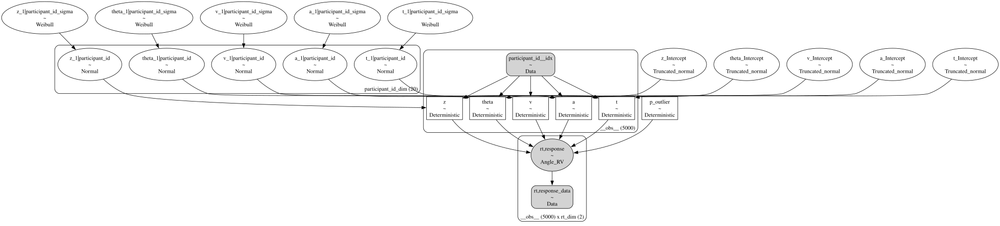

In [36]:
AngleHierModel.graph()

In [37]:
try:
    # Load pre-computed traces
    AngleHierModel.restore_traces(
        traces="scientific_workflow_hssm/idata/angle_hier/traces.nc"
    )
except Exception:
    # Sample posterior
    angle_hier_idata = AngleHierModel.sample(
        chains=2,
        sampler="numpyro",
        tune=500,
        draws=500,
    )

    # Sample posterior predictive
    AngleHierModel.sample_posterior_predictive(draws=200, safe_mode=True)

    # Save Model
    AngleHierModel.save_model(
        model_name="angle_hier",
        allow_absolute_base_path=True,
        base_path="scientific_workflow_hssm/idata/",
        save_traces_only=True,
    )

Using default initvals. 



NUTS[numpyro]: [v_Intercept, v_1|participant_id_sigma, v_1|participant_id, a_Intercept, a_1|participant_id_sigma, a_1|participant_id, z_Intercept, z_1|participant_id_sigma, z_1|participant_id, t_Intercept, t_1|participant_id_sigma, t_1|participant_id, theta_Intercept, theta_1|participant_id_sigma, theta_1|participant_id]


  0%|          | 0/1000 [00:00<?, ?it/s]

warmup:   5%|▌         | 50/1000 [00:12<03:54,  4.06it/s, 31 steps of size 3.12e-03. acc. prob=0.73]

warmup:  10%|█         | 100/1000 [00:22<03:15,  4.61it/s, 63 steps of size 7.60e-03. acc. prob=0.76]

...

sample: 100%|██████████| 1000/1000 [02:39<00:00,  6.29it/s, 63 steps of size 8.02e-02. acc. prob=0.93]

We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


dt=None, we use the traces assigned to the HSSM object as datatree.


No posterior_predictive samples found. Generating posterior_predictive samples using the provided DataTree object and the original data. This will modify the provided DataTree object, or if not provided, the traces object stored inside the model.


ipykernel_90485/1104844712.py:1: FutureWarning: plot_predictive_mean/plot_predictive_samples are deprecated; use uncertainty=None (mean only), 'samples', 'band', or 'both' instead.
  ax = hssm.plotting.plot_model_cartoon(


Output()

Output()

Output()

Output()

Output()

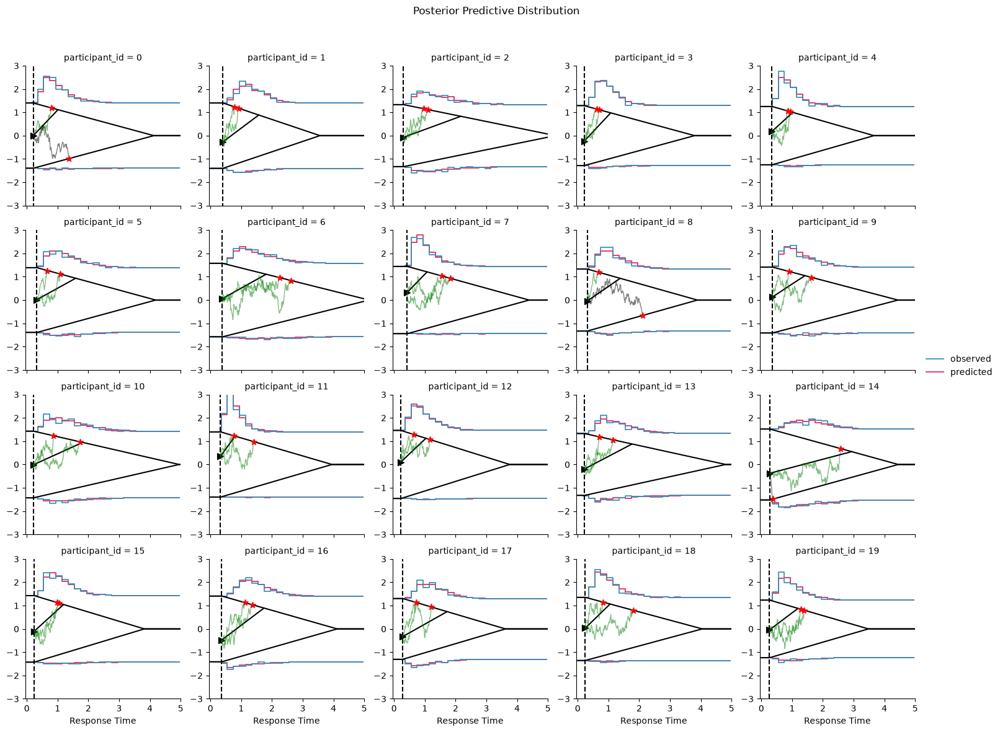

In [38]:
ax = hssm.plotting.plot_model_cartoon(
    AngleHierModel,
    col="participant_id",
    col_wrap=5,
    n_samples=10,
    bin_size=0.2,
    plot_predictive_mean=True,
    plot_predictive_samples=False,
    # extra arguments for the underlying plot_model_cartoon() function
    n_trajectories=2,
);

We can up it one notch and include the parameter uncertainty in the `model_cartoon_plot()`. This helps us assess how certain we are about the setting of the boundary collapse here.
Let's see what that looks like!

No posterior_predictive samples found. Generating posterior_predictive samples using the provided DataTree object and the original data. This will modify the provided DataTree object, or if not provided, the traces object stored inside the model.


ipykernel_90485/1339275400.py:1: FutureWarning: plot_predictive_mean/plot_predictive_samples are deprecated; use uncertainty=None (mean only), 'samples', 'band', or 'both' instead.
  ax = hssm.plotting.plot_model_cartoon(


Output()

Output()

Output()

...

Output()

Output()

Output()

Output()

Output()

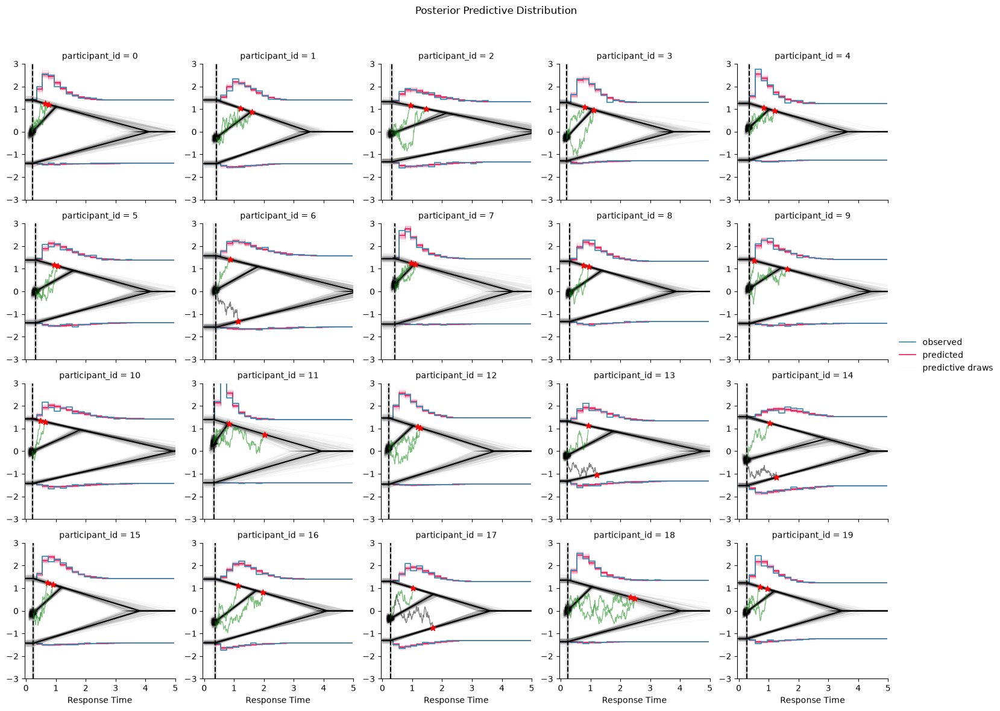

In [39]:
ax = hssm.plotting.plot_model_cartoon(
    AngleHierModel,
    col="participant_id",
    col_wrap=5,
    n_samples=50,
    bin_size=0.2,
    plot_predictive_mean=True,
    plot_predictive_samples=True,
    # extra arguments for the underlying plot_model_cartoon() function
    n_trajectories=2,
);

#### Angle (theta) parameter Bayesian t-test

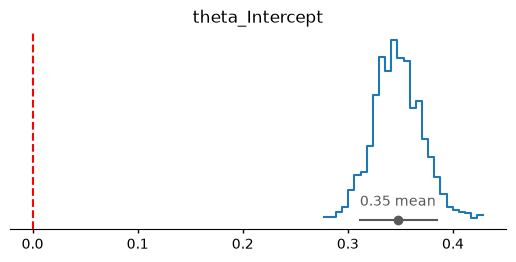

In [40]:
pc = az.plot_dist(AngleHierModel.traces, var_names=["theta_Intercept"], kind="hist")
az.add_lines(
    pc,
    values={"theta_Intercept": 0},
    orientation="vertical",
    visuals={"ref_line": dict(color="red", linestyle="--")},
)

<Axes: title={'center': 'Posterior Predictive Distribution'}, xlabel='Response Time (sign = choice)', ylabel='Density'>

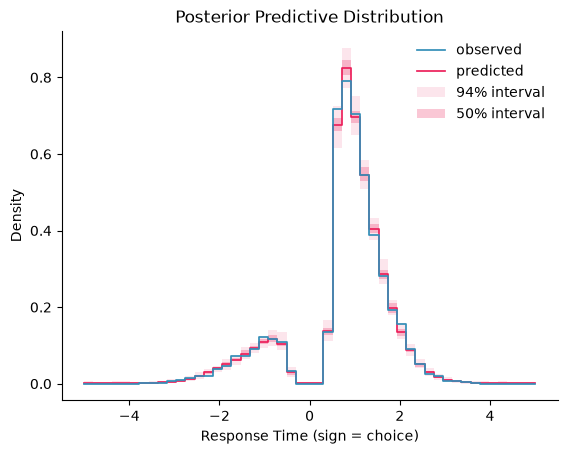

In [41]:
# Posterior predictive
AngleHierModel.plot_predictive(step=True, col_wrap=5, bins=np.linspace(-5, 5, 50))

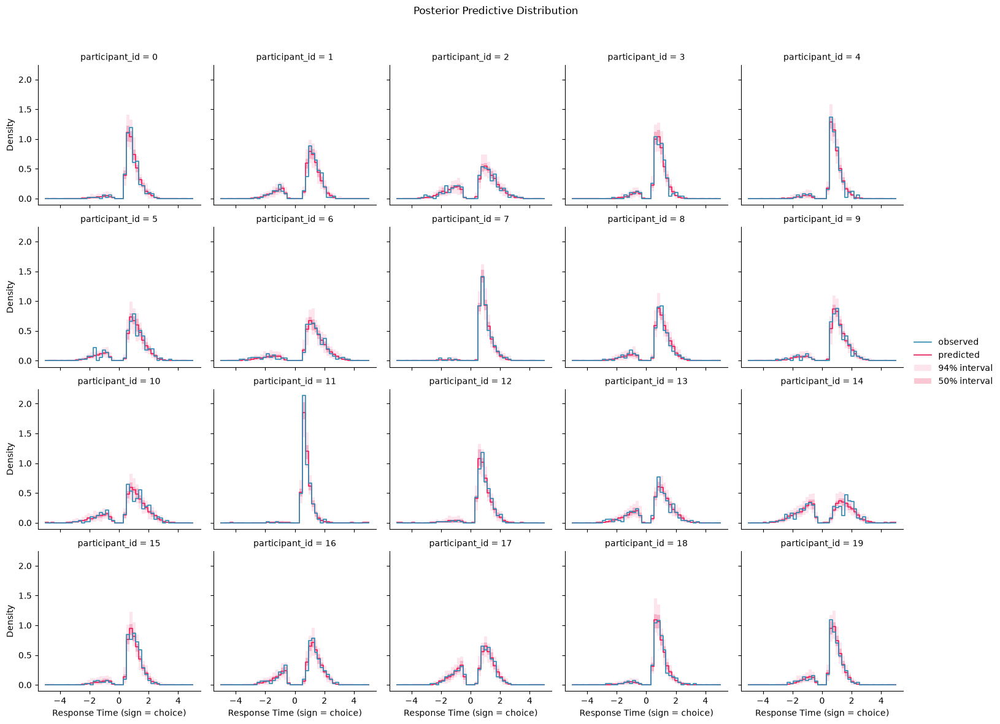

In [42]:
# Posterior predictive
AngleHierModel.plot_predictive(
    step=True, col="participant_id", col_wrap=5, bins=np.linspace(-5, 5, 50)
)

Visually it seems like we did improve the fit (even though the difference in visual improvement is much less than what we had witnessed introducing the hierarchy in the first place). 

Let us corroborate the visual intuition via formal model comparison.

#### Quantitative Model Comparison

In [43]:
az.compare(
    {
        "DDM": BasicDDMModel.traces,
        "DDM Hierarchical": DDMHierModel.traces,
        "Angle Hierarchical": AngleHierModel.traces,
    }
)

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
Angle Hierarchical,0,0.0,0.0,NaN,,,78.6,-4700.0,73.0,1.0
DDM Hierarchical,1,-220.0,17.0,1.0,,1 k̂ > 0.67,74.6,-5000.0,76.0,0.0
DDM,2,-910.0,36.0,1.0,,,5.1,-5600.0,75.0,0.0


Good, introducing the `angle` model seemed to have helped us quite a bit, even though, as intuited by the simple visual inspection, the improvement in `elpd_loo` is not as 
the improvement in going from a simple model toward a hierarchical model (even though the actual SSM was misspecified).

So what next? On the surface, it looks like we have a model that fits our data quite well. 


Let's take another look at our data to identify more patterns that we may not capture with out current efforts.



### Further EDA

Maybe it is time to look more directly at the effects of our experiment manipulations.

Below are a few graphs to understand what might be happening.

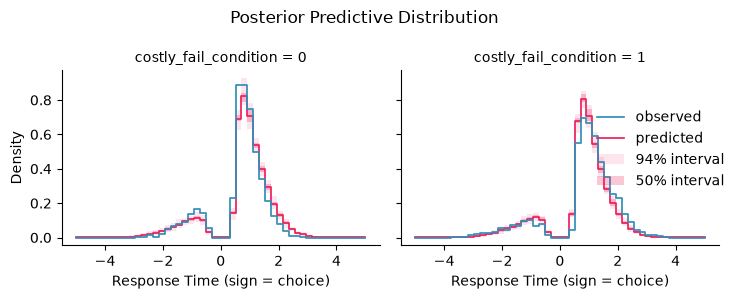

In [44]:
# Posterior predictive
AngleHierModel.plot_predictive(
    step=True, col="costly_fail_condition", bins=np.linspace(-5, 5, 50)
)
plt.tight_layout()

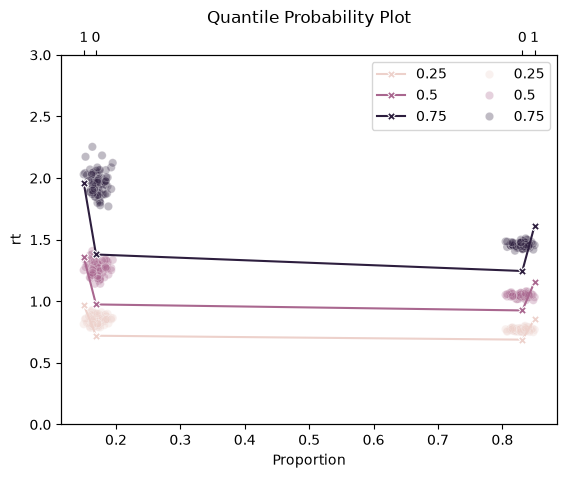

In [45]:
ax = hssm.plotting.plot_quantile_probability(
    AngleHierModel,
    cond="costly_fail_condition",
)
ax.set_ylim(0, 3);

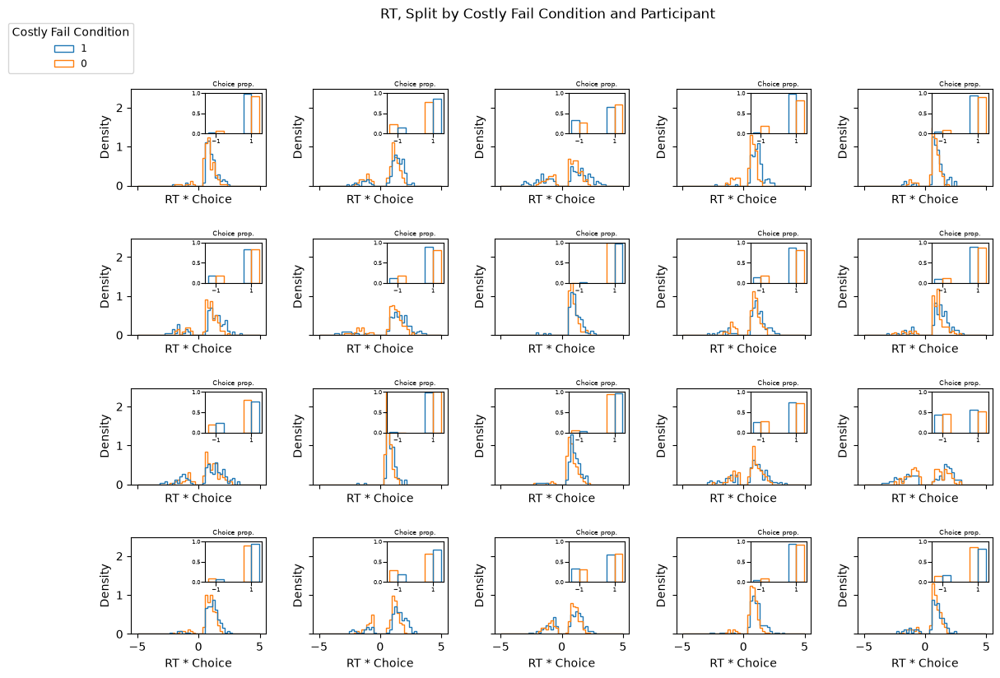

In [46]:
plot_rt_hists(
    workshop_data,
    by_participant=True,
    split_by_column="costly_fail_condition",
    inset_plot="choice_proportion",
)

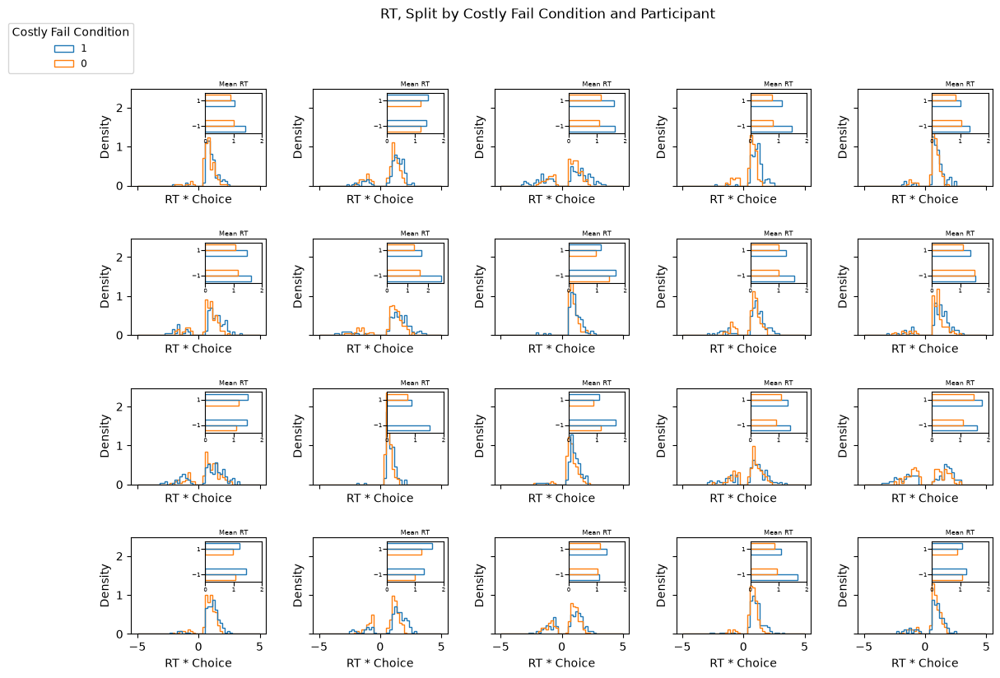

In [47]:
plot_rt_hists(
    workshop_data,
    by_participant=True,
    split_by_column="costly_fail_condition",
    inset_plot="rt_mean",
)

We can identify two patterns. 

1. On average in the `costly_fail_condition` participants seem to make slightly fewer mistakes
2. On average in the `costly_fail_condition` participants seem to take a little longer for their choices!

This meshes with how we expect the incentives to act. Participants should be slightly more cautious to get it right, if mistakes are costly!

In the contect of SSMs, this is usually mapped on to the `decision threshold` (parameter `a`), so maybe we should try to incorporate the `costly_fail_condition` in the regression
function for that parameter in our model.

## Addressing costly fail condition


To include parameter specific regressions, we can rely on the `include` argument in HSSM. Let's illustrate this.

In [48]:
AngleHierModelV2 = hssm.HSSM(
    data=workshop_data,
    model="angle",
    loglik_kind="approx_differentiable",
    global_formula="y ~ (1|participant_id)",
    include=[
        {"name": "a", "formula": "a ~ (1 + C(costly_fail_condition)|participant_id)"}
    ],
    noncentered=False,
)

Model initialized successfully.


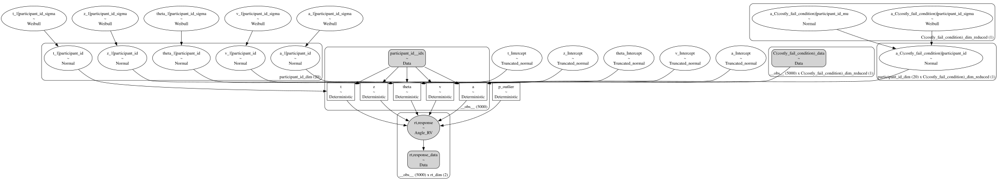

In [49]:
AngleHierModelV2.graph()

In [50]:
try:
    # Load pre-computed traces
    AngleHierModelV2.restore_traces(
        traces="scientific_workflow_hssm/idata/angle_hier_v2/traces.nc"
    )
except Exception:
    # Sample posterior
    angle_hier_idata = AngleHierModelV2.sample(
        chains=2,
        sampler="numpyro",
        tune=500,
        draws=500,
    )

    # Sample posterior predictive
    AngleHierModelV2.sample_posterior_predictive(draws=200, safe_mode=True)

    # Save Model
    AngleHierModelV2.save_model(
        model_name="angle_hier_v2",
        allow_absolute_base_path=True,
        base_path="scientific_workflow_hssm/idata/",
        save_traces_only=True,
    )

Using default initvals. 



NUTS[numpyro]: [v_Intercept, v_1|participant_id_sigma, v_1|participant_id, a_Intercept, a_1|participant_id_sigma, a_1|participant_id, a_C(costly_fail_condition)|participant_id_mu, a_C(costly_fail_condition)|participant_id_sigma, a_C(costly_fail_condition)|participant_id, z_Intercept, z_1|participant_id_sigma, z_1|participant_id, t_Intercept, t_1|participant_id_sigma, t_1|participant_id, theta_Intercept, theta_1|participant_id_sigma, theta_1|participant_id]


  0%|          | 0/1000 [00:00<?, ?it/s]

warmup:   5%|▌         | 50/1000 [00:11<03:44,  4.23it/s, 127 steps of size 2.92e-03. acc. prob=0.73]

warmup:  10%|█         | 100/1000 [00:23<03:31,  4.26it/s, 127 steps of size 4.31e-03. acc. prob=0.76]

...

sample: 100%|██████████| 1000/1000 [02:31<00:00,  7.47it/s, 63 steps of size 1.04e-01. acc. prob=0.88]

sample: 100%|██████████| 1000/1000 [02:31<00:00,  6.62it/s, 63 steps of size 1.04e-01. acc. prob=0.88]

We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


dt=None, we use the traces assigned to the HSSM object as datatree.


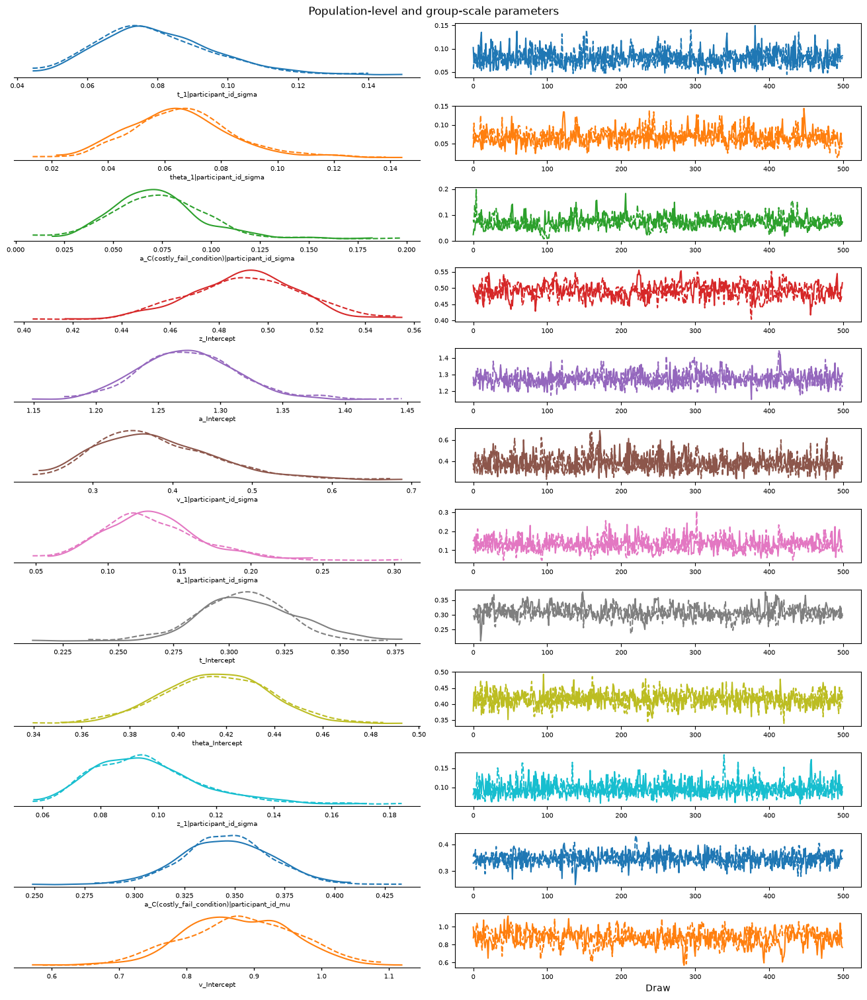

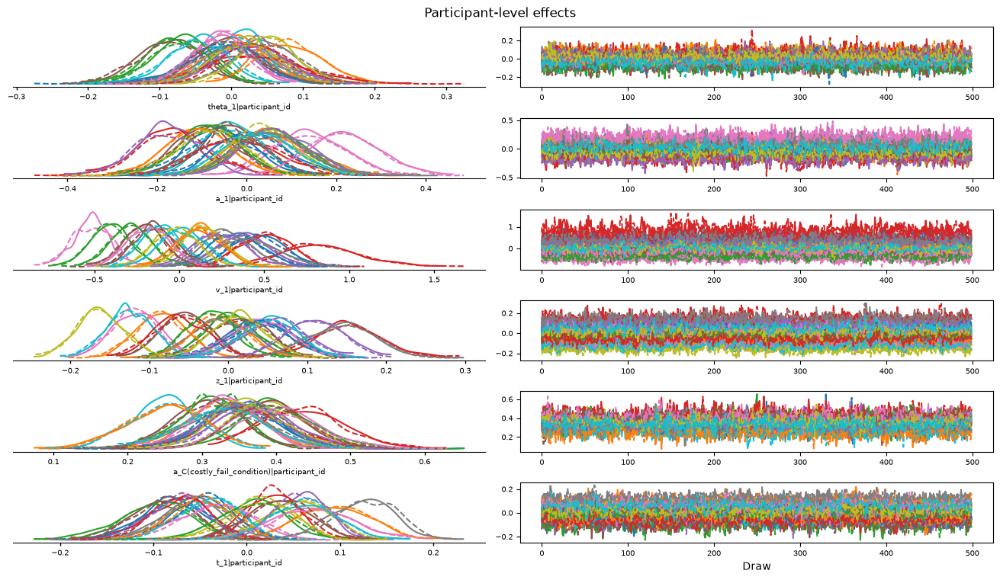

In [51]:
plot_grouped_traces(AngleHierModelV2.traces)

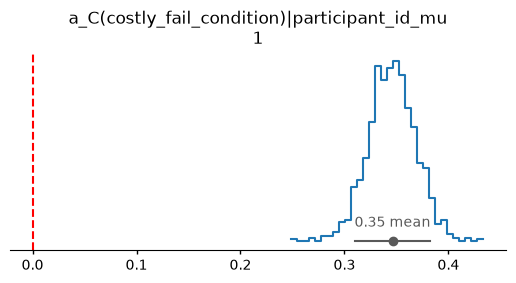

In [52]:
pc = az.plot_dist(
    AngleHierModelV2.traces,
    var_names=["a_C(costly_fail_condition)|participant_id_mu"],
    kind="hist",
)
az.add_lines(
    pc,
    values={"a_C(costly_fail_condition)|participant_id_mu": 0},
    orientation="vertical",
    visuals={"ref_line": dict(color="red", linestyle="--")},
)

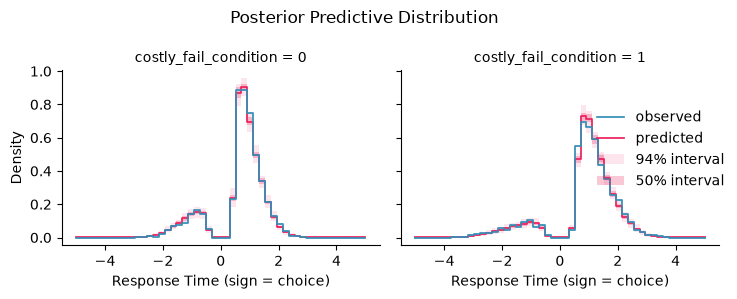

In [53]:
# Posterior predictive
AngleHierModelV2.plot_predictive(
    step=True,
    # row = 'participant_id',
    col="costly_fail_condition",
    bins=np.linspace(-5, 5, 50),
)
plt.tight_layout()
plt.show()

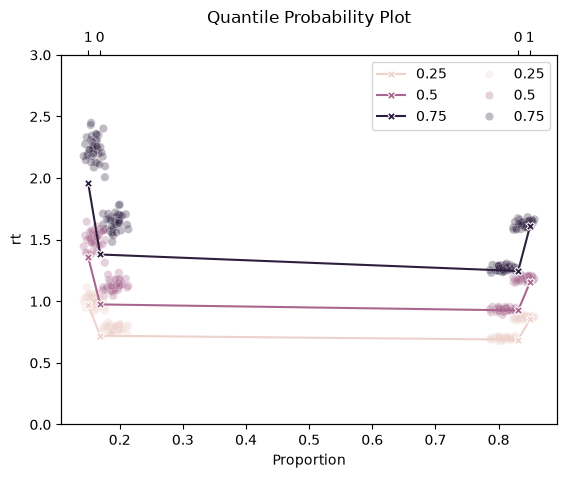

In [54]:
ax = hssm.plotting.plot_quantile_probability(
    AngleHierModelV2,
    cond="costly_fail_condition",
)
ax.set_ylim(0, 3);

Quite an improvement!
Let's see what our quantitative model comparison metrics say.


### Quantitative Model Comparison

In [55]:
az.compare(
    {
        "DDM": BasicDDMModel.traces,
        "DDM Hierarchical": DDMHierModel.traces,
        "Angle Hierarchical": AngleHierModel.traces,
        "Angle Hierarchical Cost": AngleHierModelV2.traces,
    }
)

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
Angle Hierarchical Cost,0,0.0,0.0,NaN,,,88.1,-4500.0,71.0,1.0
Angle Hierarchical,1,-270.0,21.0,1.0,,,78.6,-4700.0,73.0,0.0
DDM Hierarchical,2,-480.0,25.0,1.0,,1 k̂ > 0.67,74.6,-5000.0,76.0,0.0
DDM,3,-1170.0,41.0,1.0,,,5.1,-5600.0,75.0,0.0


Good, we now incorporated the `costly_fail_condition` in a conceptually coherent manner. 

Let's take a look at `difficulty` next. 

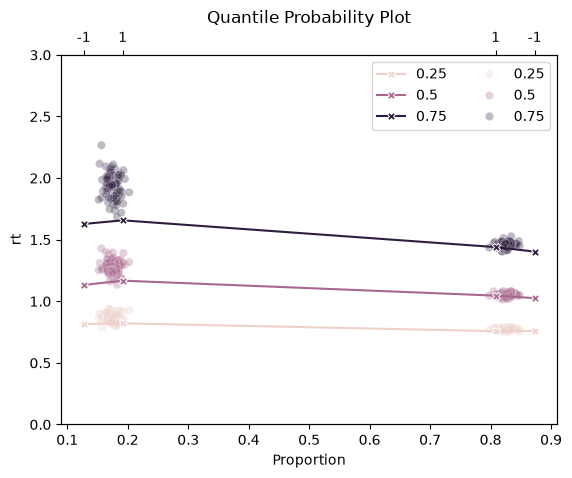

In [56]:
ax = hssm.plotting.plot_quantile_probability(
    AngleHierModelV2,
    cond="quantile_difficulty_binary",
)
ax.set_ylim(0, 3);

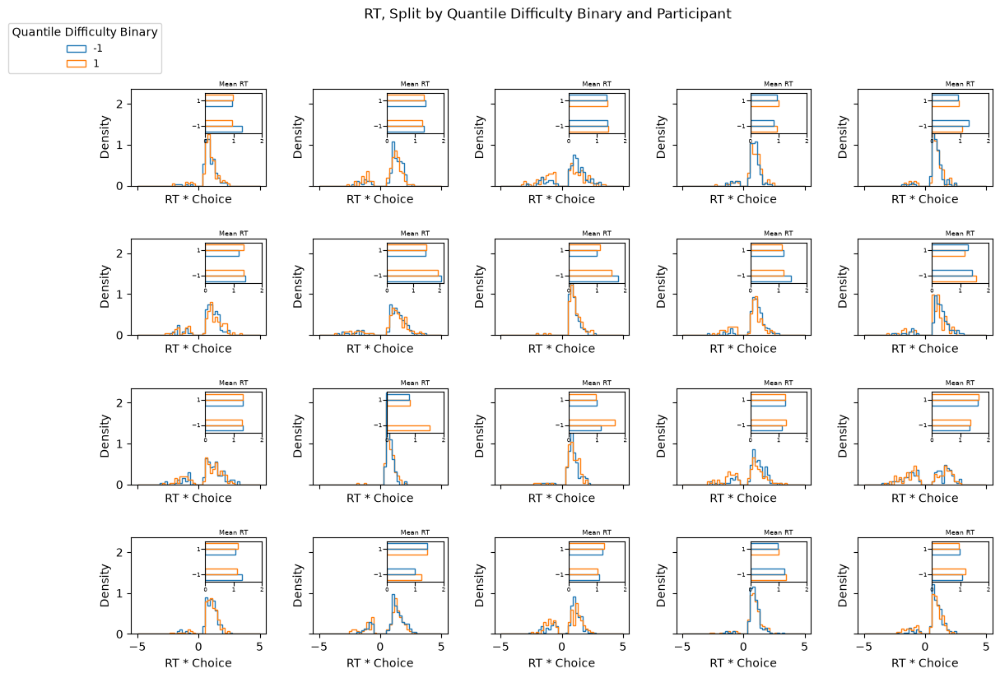

In [57]:
plot_rt_hists(
    workshop_data,
    by_participant=True,
    split_by_column="quantile_difficulty_binary",
    inset_plot="rt_mean",
)

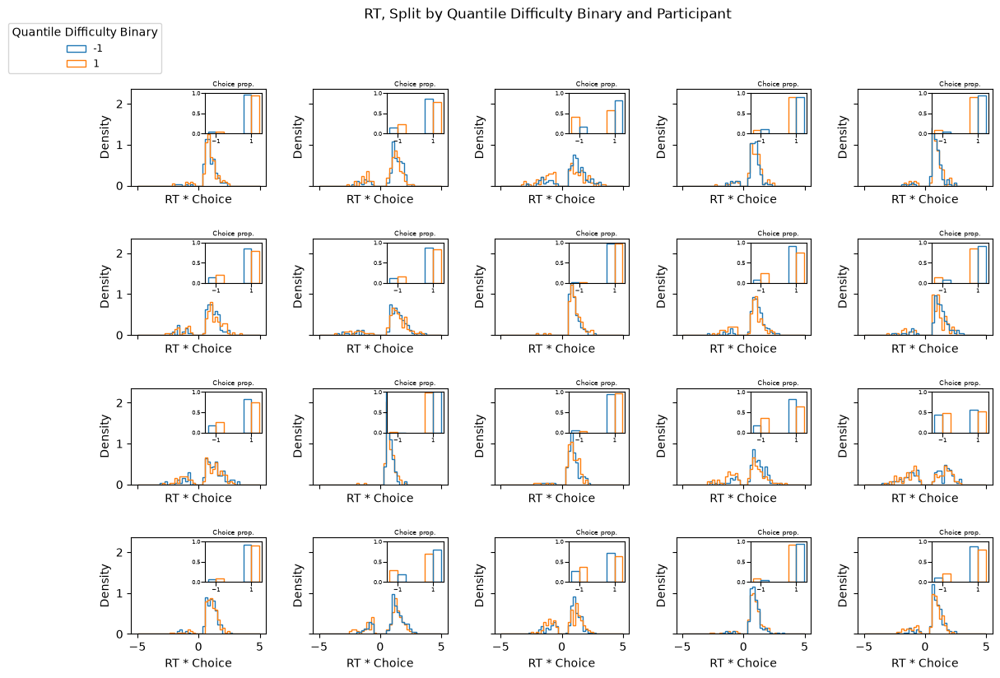

In [58]:
plot_rt_hists(
    workshop_data,
    by_participant=True,
    split_by_column="quantile_difficulty_binary",
    inset_plot="choice_proportion",
)

We see a similar pattern. Difficulty affects choice probability, however the effect on RT is less clear.

What parameter should difficulty map onto? Usually it maps onto the **rate of evidence accumulation**, which is the *drift* (`v`) parameter most SSMs.

We will move ahead and try this. To add specialized regression for `v` we can add another parameter dictionary to the list we pass to `include`.



## Addressing difficulty

In [59]:
AngleHierModelV3 = hssm.HSSM(
    data=workshop_data,
    model="angle",
    loglik_kind="approx_differentiable",
    global_formula="y ~ (1|participant_id)",
    include=[
        {"name": "a", "formula": "a ~ (1 + C(costly_fail_condition)|participant_id)"},
        {"name": "v", "formula": "v ~ (1 + continuous_difficulty|participant_id)"},
    ],
    noncentered=False,
)

Model initialized successfully.


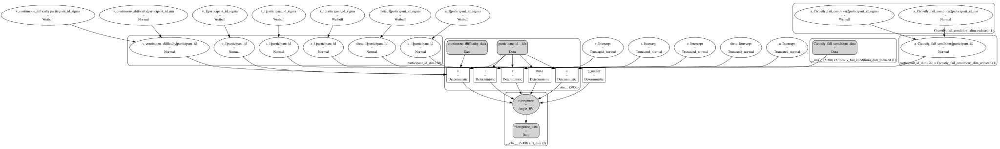

In [60]:
AngleHierModelV3.graph()

In [61]:
try:
    # Load pre-computed traces
    AngleHierModelV3.restore_traces(
        traces="scientific_workflow_hssm/idata/angle_hier_v3/traces.nc"
    )
except Exception:
    # Sample posterior
    angle_hier_idata = AngleHierModelV3.sample(
        chains=2,
        sampler="numpyro",
        tune=500,
        draws=500,
    )

    # Sample posterior predictive
    AngleHierModelV3.sample_posterior_predictive(draws=200, safe_mode=True)

    # Save Model
    AngleHierModelV3.save_model(
        model_name="angle_hier_v3",
        allow_absolute_base_path=True,
        base_path="scientific_workflow_hssm/idata/",
        save_traces_only=True,
    )

Using default initvals. 



NUTS[numpyro]: [v_Intercept, v_1|participant_id_sigma, v_1|participant_id, v_continuous_difficulty|participant_id_mu, v_continuous_difficulty|participant_id_sigma, v_continuous_difficulty|participant_id, a_Intercept, a_1|participant_id_sigma, a_1|participant_id, a_C(costly_fail_condition)|participant_id_mu, a_C(costly_fail_condition)|participant_id_sigma, a_C(costly_fail_condition)|participant_id, z_Intercept, z_1|participant_id_sigma, z_1|participant_id, t_Intercept, t_1|participant_id_sigma, t_1|participant_id, theta_Intercept, theta_1|participant_id_sigma, theta_1|participant_id]


  0%|          | 0/1000 [00:00<?, ?it/s]

warmup:   5%|▌         | 50/1000 [00:14<04:27,  3.55it/s, 127 steps of size 5.15e-03. acc. prob=0.74]

warmup:  10%|█         | 100/1000 [00:22<03:14,  4.63it/s, 63 steps of size 6.58e-03. acc. prob=0.76]

...


There were 7 divergences after tuning. Increase `target_accept` or reparameterize.


We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


dt=None, we use the traces assigned to the HSSM object as datatree.


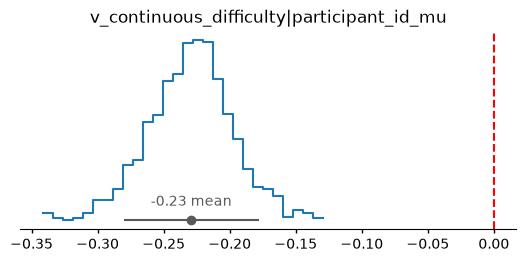

In [62]:
pc = az.plot_dist(
    AngleHierModelV3.traces,
    var_names=["v_continuous_difficulty|participant_id_mu"],
    kind="hist",
)
az.add_lines(
    pc,
    values={"v_continuous_difficulty|participant_id_mu": 0},
    orientation="vertical",
    visuals={"ref_line": dict(color="red", linestyle="--")},
)

Looks like the effect on `v` is small (to the trained eye :)), but it is significant!
Let's check if we can account for the data pattern we missed previously.

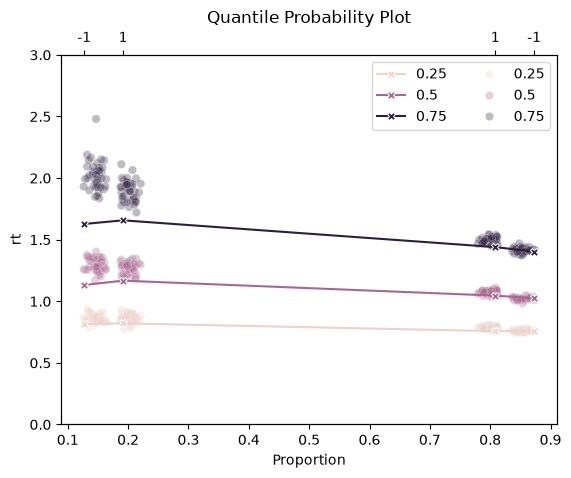

In [63]:
ax = hssm.plotting.plot_quantile_probability(
    AngleHierModelV3,
    cond="quantile_difficulty_binary",
)
ax.set_ylim(0, 3);

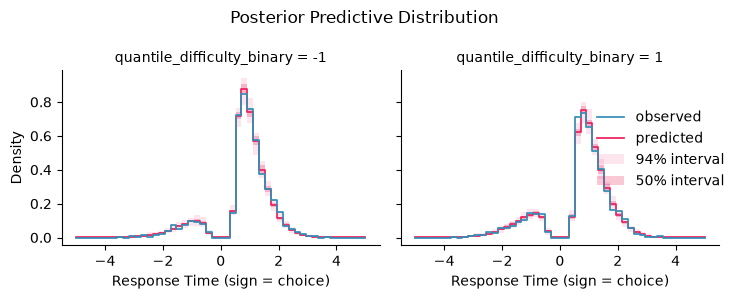

In [64]:
# Posterior predictive
AngleHierModelV3.plot_predictive(
    step=True, col="quantile_difficulty_binary", bins=np.linspace(-5, 5, 50)
)
plt.tight_layout()

Success! This looks much better.

#### Quantitative Model Comparison

In [65]:
az.compare(
    {
        "DDM": BasicDDMModel.traces,
        "DDM Hierarchical": DDMHierModel.traces,
        "Angle Hierarchical": AngleHierModel.traces,
        "Angle Hierarchical Cost": AngleHierModelV2.traces,
        "Angle Hierarchical Cost/Diff": AngleHierModelV3.traces,
    }
)

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
Angle Hierarchical Cost/Diff,0,0.0,0.0,NaN,,,90.3,-4400.0,71.0,1.0
Angle Hierarchical Cost,1,-40.0,8.4,1.0,,,88.1,-4500.0,71.0,0.0
Angle Hierarchical,2,-300.0,22.0,1.0,,,78.6,-4700.0,73.0,0.0
DDM Hierarchical,3,-520.0,27.0,1.0,,1 k̂ > 0.67,74.6,-5000.0,76.0,0.0
DDM,4,-1210.0,41.0,1.0,,,5.1,-5600.0,75.0,0.0


### Anything else?

At this point, we have a model that fits the data quite well. 

We figured that a hierarchy significantly improves our fit, that the `angle` model dominates the basic `ddm` model for our data, and we incorporated effects based on 
our experiment manipulations. 

A natural next step is to check for patterns based on more generic properties of human choice data that we may be able to reason about. 

Anything that comes to mind? Let's take another look at our dataset for some inspiration.

In [66]:
workshop_data

,response,rt,participant_id,trial,costly_fail_condition,continuous_difficulty,response_l1,bin_difficulty,quantile_difficulty,quantile_difficulty_binary,response_l1_plotting
0,1,0.556439,0,1,1,-0.277337,0,low,0,-1,1
1,1,0.741682,0,2,0,-0.810919,1,low,-1,-1,1
2,1,0.461832,0,3,0,-0.673330,1,low,-1,-1,1
3,1,0.626154,0,4,0,0.755445,1,high,1,1,1
4,1,0.651677,0,5,1,0.136755,1,high,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...
4995,1,1.039342,19,246,0,-0.612223,-1,low,-1,-1,-1
4996,1,1.587827,19,247,0,0.732396,1,high,1,1,1
4997,1,0.668594,19,248,1,-0.175321,1,low,0,-1,1
4998,1,1.616471,19,249,0,-0.630447,1,low,-1,-1,1


At risk of stating the obvious,we have a column that went unused thus far: `response_l1`, the lagged response.

Maybe this hints at some level of *stickiness* in the choice behavior? How could we incorporate this?

Let us first investigate if there is indeed such a pattern in the data!

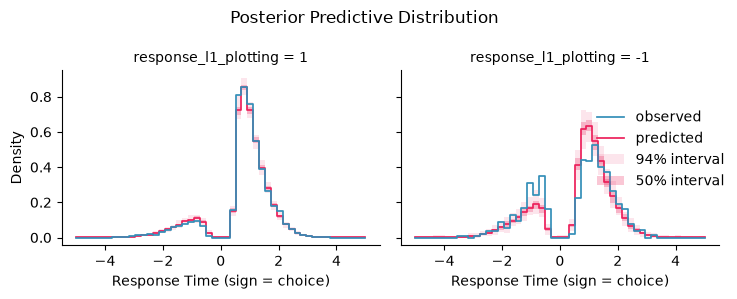

In [67]:
# Posterior predictive
AngleHierModelV3.plot_predictive(
    step=True, col="response_l1_plotting", bins=np.linspace(-5, 5, 50)
)
plt.tight_layout()

Indeed, it does seem like there is a bit of a pattern here, that we miss so far!

To incoporate choice `stickiness`, a reasonable candidate parameter is `z`, the a priori choice bias. 
Maybe this parameter is affected by the last choice taken?

Let's try to incoporate this. We will 

## Addressing Stickyness

In [68]:
AngleHierModelV4 = hssm.HSSM(
    data=workshop_data,
    model="angle",
    loglik_kind="approx_differentiable",
    global_formula="y ~ (1|participant_id)",
    include=[
        {"name": "a", "formula": "a ~ (1 + C(costly_fail_condition)|participant_id)"},
        {"name": "v", "formula": "v ~ (1 + continuous_difficulty|participant_id)"},
        {"name": "z", "formula": "z ~ (1 + response_l1|participant_id)"},
    ],
    noncentered=False,
)

Model initialized successfully.


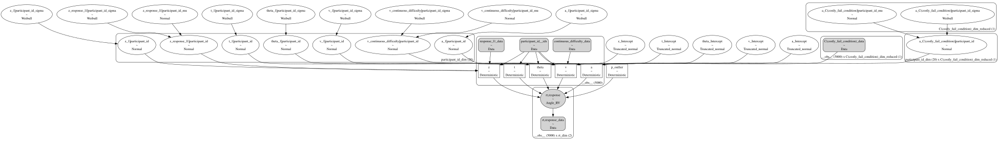

In [69]:
AngleHierModelV4.graph()

In [70]:
try:
    # Load pre-computed traces
    AngleHierModelV4.restore_traces(
        traces="scientific_workflow_hssm/idata/angle_hier_v4/traces.nc"
    )
except Exception:
    # Sample posterior
    angle_hier_idata = AngleHierModelV4.sample(
        chains=2,
        sampler="numpyro",
        tune=500,
        draws=500,
    )

    # Sample posterior predictive
    AngleHierModelV4.sample_posterior_predictive(draws=200, safe_mode=True)

    # Save Model
    AngleHierModelV4.save_model(
        model_name="angle_hier_v4",
        allow_absolute_base_path=True,
        base_path="scientific_workflow_hssm/idata/",
        save_traces_only=True,
    )

Using default initvals. 



NUTS[numpyro]: [v_Intercept, v_1|participant_id_sigma, v_1|participant_id, v_continuous_difficulty|participant_id_mu, v_continuous_difficulty|participant_id_sigma, v_continuous_difficulty|participant_id, a_Intercept, a_1|participant_id_sigma, a_1|participant_id, a_C(costly_fail_condition)|participant_id_mu, a_C(costly_fail_condition)|participant_id_sigma, a_C(costly_fail_condition)|participant_id, z_Intercept, z_1|participant_id_sigma, z_1|participant_id, z_response_l1|participant_id_mu, z_response_l1|participant_id_sigma, z_response_l1|participant_id, t_Intercept, t_1|participant_id_sigma, t_1|participant_id, theta_Intercept, theta_1|participant_id_sigma, theta_1|participant_id]


  0%|          | 0/1000 [00:00<?, ?it/s]

warmup:   0%|          | 0/1000 [00:13<?, ?it/s, 127 steps of size 1.32e-03. acc. prob=0.68]

warmup:   3%|▎         | 27/1000 [00:15<09:02,  1.79it/s, 1023 steps of size 2.50e-03. acc. prob=0.69]

...

There were 2 divergences after tuning. Increase `target_accept` or reparameterize.


We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


dt=None, we use the traces assigned to the HSSM object as datatree.


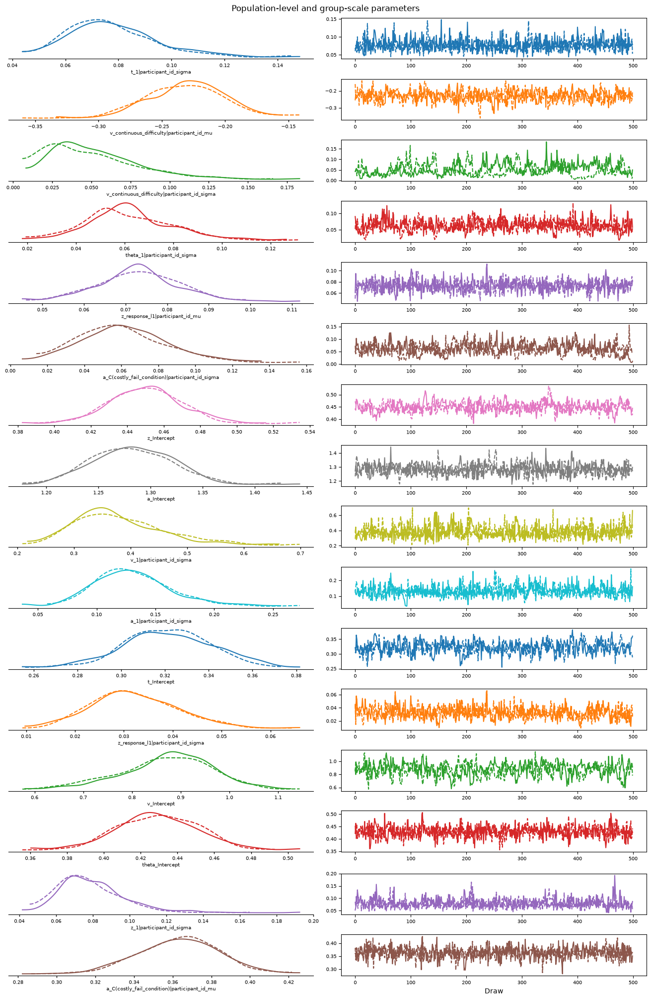

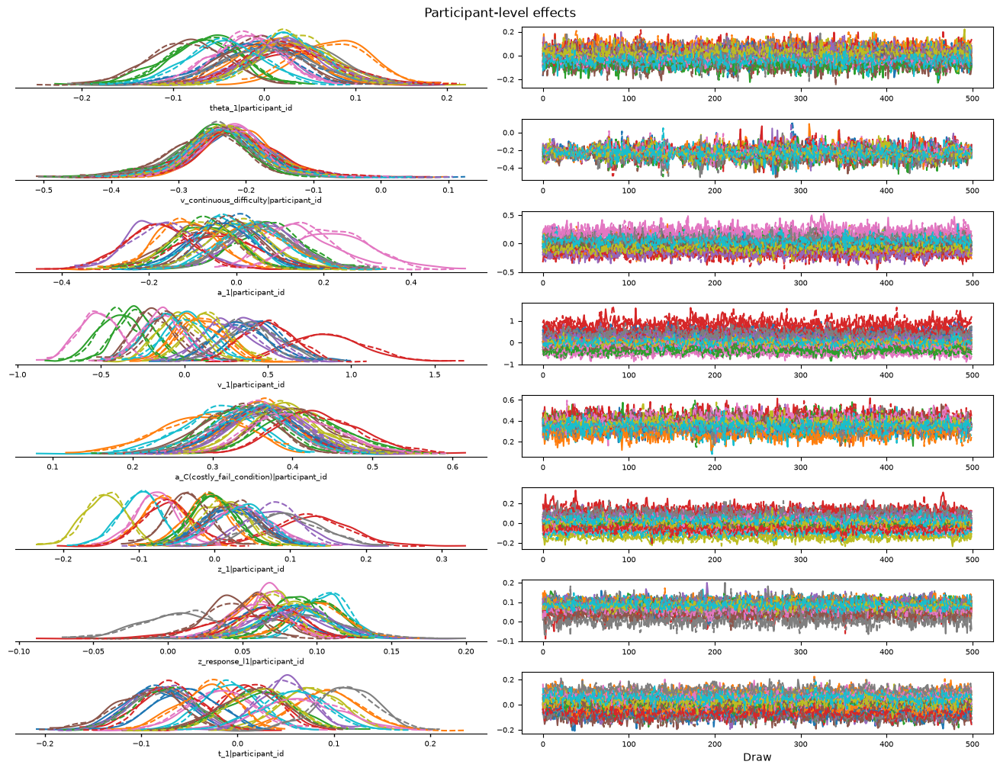

In [71]:
plot_grouped_traces(AngleHierModelV4.traces, show_divergences=False)

** Note **:

We can see some rather interesting artifacts in the chains above. Around samples `300-375` it looks like our solid-blue chain got quite stuck. This indicates some problems with the posterior geometry for this model. 
One diagnostic that can be helpful here whether or not we observe a lot of `divergences` during sampling. 

The two grouped trace figures above hide divergences. Below, we repeat the same complete parameter groups with the default divergence markers enabled.


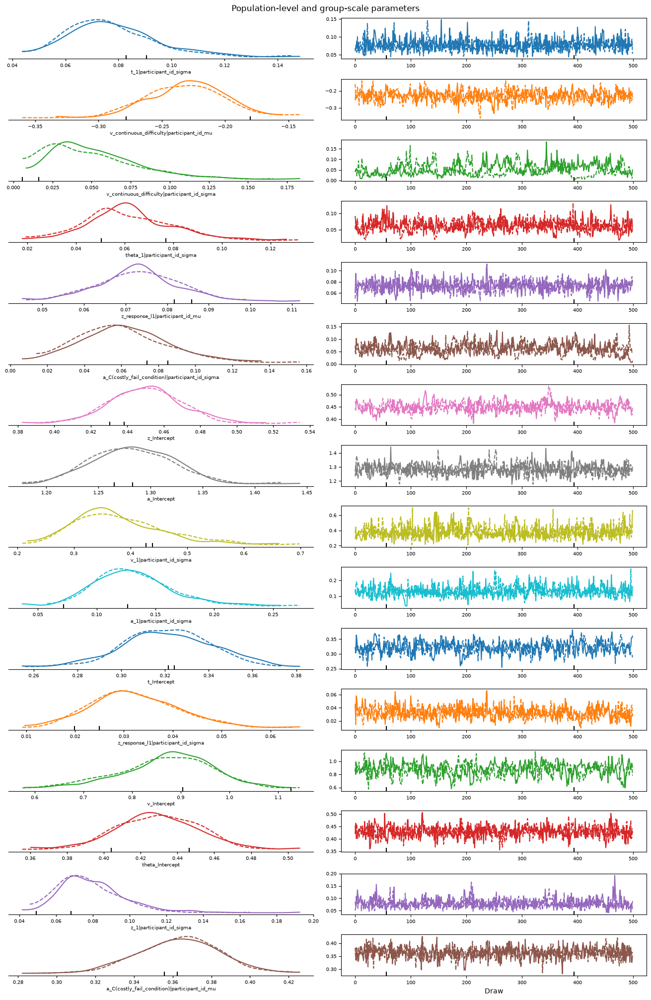

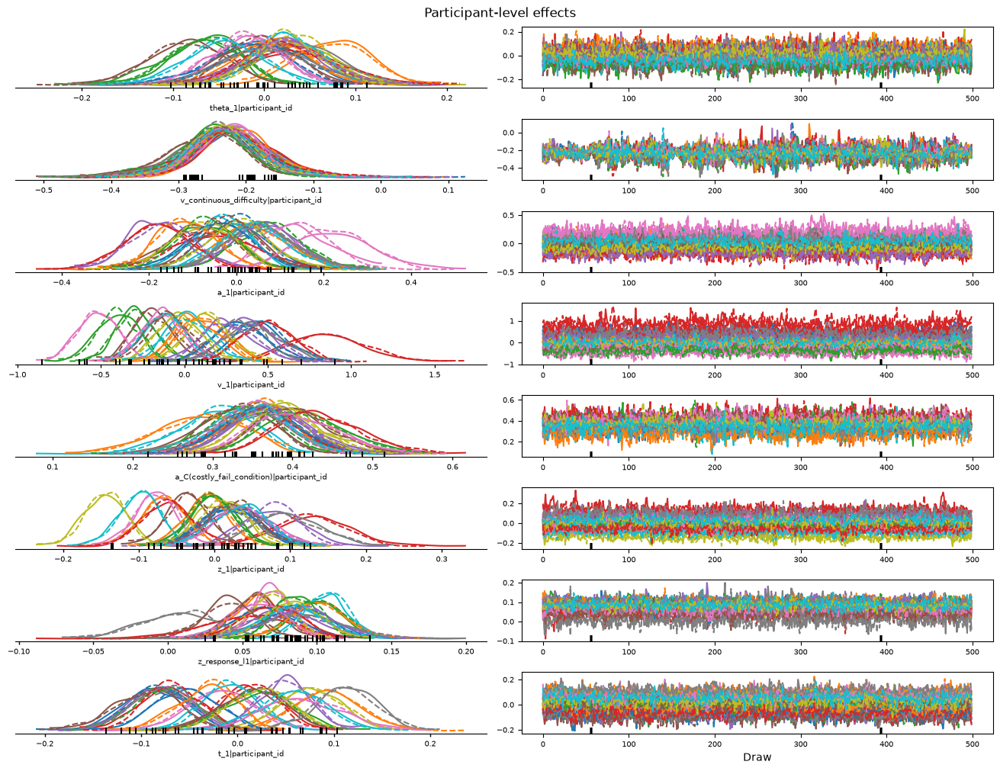

In [72]:
plot_grouped_traces(AngleHierModelV4.traces)

Indeed, we observe a few divergences here... as rigorous scientists, we should now try to get to the bottom of this phenomenon (it happens often if one tries hierarchical models naively on real experimental data).
In the context of this tutorial, we will let it slide however. It would warrant a longer detour.

Let's move on and focus on whether or not we actually identify a significant **choice stickyness** effect with our analysis:

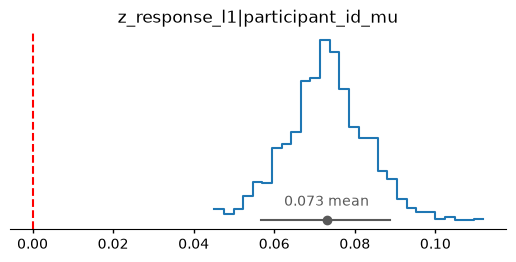

In [73]:
pc = az.plot_dist(
    AngleHierModelV4.traces, var_names=["z_response_l1|participant_id_mu"], kind="hist"
)
az.add_lines(
    pc,
    values={"z_response_l1|participant_id_mu": 0},
    orientation="vertical",
    visuals={"ref_line": dict(color="red", linestyle="--")},
)

We observe a significant effect on the `z` parameter, in fact a mean effect of `0.073` insinuate a fairly big effect of choice stickyness.
In direct comparison, we might expect this effect to overall have a larger impact on our model fit than the effect of difficulty on `v`, which we investigated in the 
previous section.

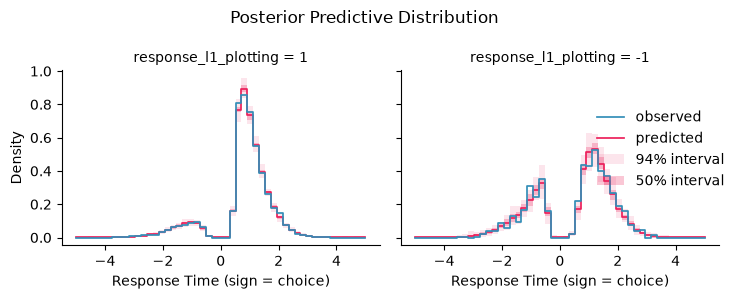

In [74]:
# Posterior predictive
AngleHierModelV4.plot_predictive(
    step=True, col="response_l1_plotting", bins=np.linspace(-5, 5, 50)
)
plt.tight_layout()

#### Quantitative Model Comparison

In [75]:
az.compare(
    {
        "DDM": BasicDDMModel.traces,
        "DDM Hierarchical": DDMHierModel.traces,
        "Angle Hierarchical": AngleHierModel.traces,
        "Angle Hierarchical Cost": AngleHierModelV2.traces,
        "Angle Hierarchical Cost/Diff": AngleHierModelV3.traces,
        "Angle Hierarchical Cost/Diff/Sticky": AngleHierModelV4.traces,
    }
)

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
Angle Hierarchical Cost/Diff/Sticky,0,0.0,0.0,NaN,,,102.0,-4300.0,71.0,0.97
Angle Hierarchical Cost/Diff,1,-110.0,15.0,1.0,,,90.3,-4400.0,71.0,0.03
Angle Hierarchical Cost,2,-140.0,17.0,1.0,,,88.1,-4500.0,71.0,0.00
Angle Hierarchical,3,-410.0,26.0,1.0,,,78.6,-4700.0,73.0,0.00
DDM Hierarchical,4,-630.0,29.0,1.0,,1 k̂ > 0.67,74.6,-5000.0,76.0,0.00
DDM,5,-1320.0,43.0,1.0,,,5.1,-5600.0,75.0,0.00


And indeed, the drop in`elpd_loo` is even more substantial, than the improvement generated by incorporating the `difficulty` effect.

#### Taking Stock

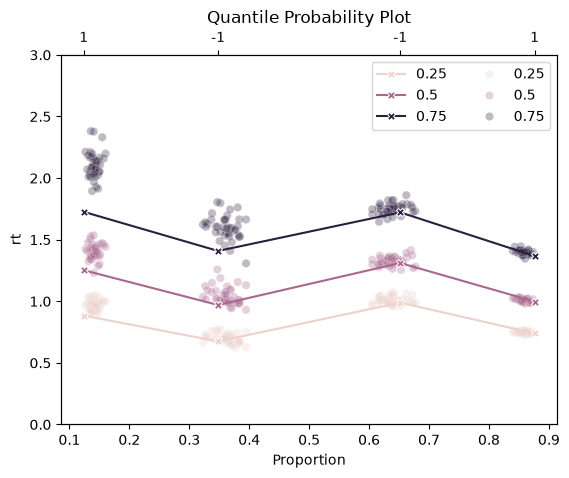

In [76]:
ax = hssm.plotting.plot_quantile_probability(
    AngleHierModelV4,
    cond="response_l1_plotting",
)
ax.set_ylim(0, 3);

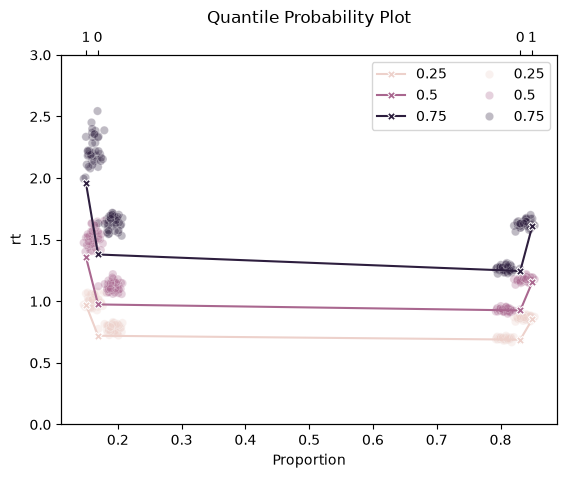

In [77]:
ax = hssm.plotting.plot_quantile_probability(
    AngleHierModelV4,
    cond="costly_fail_condition",
)
ax.set_ylim(0, 3);

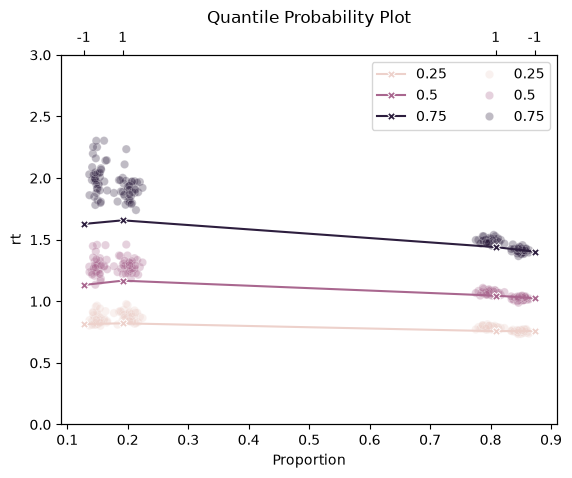

In [78]:
ax = hssm.plotting.plot_quantile_probability(
    AngleHierModelV4,
    cond="quantile_difficulty_binary",
)
ax.set_ylim(0, 3);

## Sanity Check, was the hierarchy really necessary

In [79]:
AngleModelV5 = hssm.HSSM(
    data=workshop_data,
    model="angle",
    loglik_kind="approx_differentiable",
    global_formula="y ~ 1",
    include=[
        {"name": "a", "formula": "a ~ 1 + C(costly_fail_condition)"},
        {"name": "v", "formula": "v ~ 1 + continuous_difficulty"},
        {"name": "z", "formula": "z ~ 1 + response_l1"},
    ],
    noncentered=False,
)

Model initialized successfully.


In [80]:
try:
    # Load pre-computed traces
    AngleModelV5.restore_traces(
        traces="scientific_workflow_hssm/idata/angle_v5/traces.nc"
    )
except Exception:
    # Sample posterior
    angle_hier_idata = AngleModelV5.sample(
        chains=2,
        sampler="numpyro",
        tune=500,
        draws=500,
    )

    # Sample posterior predictive
    AngleModelV5.sample_posterior_predictive(draws=200, safe_mode=True)

    # Save Model
    AngleModelV5.save_model(
        model_name="angle_v5",
        allow_absolute_base_path=True,
        base_path="scientific_workflow_hssm/idata/",
        save_traces_only=True,
    )

Using default initvals. 



NUTS[numpyro]: [v_continuous_difficulty, v_Intercept_centered, a_C(costly_fail_condition), a_Intercept_centered, z_response_l1, z_Intercept_centered, t_Intercept, theta_Intercept]


  0%|          | 0/1000 [00:00<?, ?it/s]

warmup:   5%|▌         | 50/1000 [00:03<00:57, 16.64it/s, 15 steps of size 8.09e-03. acc. prob=0.74]

warmup:  10%|█         | 100/1000 [00:05<00:48, 18.47it/s, 31 steps of size 8.25e-03. acc. prob=0.76]

...

sample: 100%|██████████| 1000/1000 [00:40<00:00, 27.27it/s, 15 steps of size 2.33e-01. acc. prob=0.94]

sample: 100%|██████████| 1000/1000 [00:40<00:00, 24.53it/s, 15 steps of size 2.33e-01. acc. prob=0.94]


We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


dt=None, we use the traces assigned to the HSSM object as datatree.


In [81]:
az.compare(
    {
        "DDM": BasicDDMModel.traces,
        "DDM Hierarchical": DDMHierModel.traces,
        "Angle Hierarchical": AngleHierModel.traces,
        "Angle Hierarchical Cost": AngleHierModelV2.traces,
        "Angle Hierarchical Cost/Diff": AngleHierModelV3.traces,
        "Angle Hierarchical Cost/Diff/Sticky": AngleHierModelV4.traces,
        "Angle Cost/Diff/Sticky": AngleModelV5.traces,
    }
)

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
Angle Hierarchical Cost/Diff/Sticky,0,0.0,0.0,NaN,,,102.0,-4300.0,71.0,0.97
Angle Hierarchical Cost/Diff,1,-110.0,15.0,1.0,,,90.3,-4400.0,71.0,0.03
Angle Hierarchical Cost,2,-140.0,17.0,1.0,,,88.1,-4500.0,71.0,0.00
Angle Hierarchical,3,-410.0,26.0,1.0,,,78.6,-4700.0,73.0,0.00
DDM Hierarchical,4,-630.0,29.0,1.0,,1 k̂ > 0.67,74.6,-5000.0,76.0,0.00
Angle Cost/Diff/Sticky,5,-680.0,33.0,1.0,,,8.7,-5000.0,70.0,0.00
DDM,6,-1320.0,43.0,1.0,,,5.1,-5600.0,75.0,0.00


## The End:

So far so good, we completed a rather comprehensive model exploration and we generated quite a few insights!
We could obviously go on and try more and more complex models and maybe there is more to find out here... we leave this up to you and hope that HSSM will continue to help you along the way :).

## Pointers to advanced Topics

We are scratching only the surface of what cann be done with [HSSM](https://github.com/lnccbrown/HSSM/), let alone the broader eco-system supporting [simulation based inference (SBI)](https://simulation-based-inference.org/).

Check out our simulator package, [ssm-simulators](https://github.com/lnccbrown/ssm-simulators) as well as our our little neural network library for training [LANs](https://elifesciences.org/articles/65074), [lanfactory](https://github.com/lnccbrown/LANfactory). 

Exciting work is being done (more on this in the next tutorial) on connecting to other packages in the wider eco-system, such as [BayesFlow](https://bayesflow.org/) as well as the [sbi](https://sbi-dev.github.io/sbi/v0.24.0/) package.

Here is a taste of advanced topics with links to corresponding tutorials:

- [Variational Inference with HSSM](https://lnccbrown.github.io/HSSM/tutorials/variational_inference/)
- [Build PyMC models with HSSM random variables](https://lnccbrown.github.io/HSSM/tutorials/pymc/)
- [Connect compiled models to third party MCMC libraries](https://lnccbrown.github.io/HSSM/tutorials/compile_logp/)
- [Construct custom models from simulators and contributed likelihoods](https://lnccbrown.github.io/HSSM/tutorials/jax_callable_contribution_onnx_example/)
- [Using link functions to transform parameters](https://lnccbrown.github.io/HSSM/api/link/#hssm.Link)

you will find this and a lot more information in the [official documentation](https://lnccbrown.github.io/HSSM/)
